# C09c — FZ301 coordinate attainment and RAFT composition
Original 54 paired cases: **OG, NS10, OG→RAFT, NS11=RAFT(NS10)**. No generation, classifier fitting, or GPU inference. Uses the exact project C04 FZ301 extractor (including its identity-based coreference proxy), embedded below.

**Diagnostic bands are not historical optimization targets.** Historical interventions used heterogeneous medians, one-sided targets and running controls. This audit measures final-text coordinates against independent RAID **training-human** central 80% intervals. Primary: same genre, nearest 40 human documents by log word-count distance to **OG**, with the reference set fixed across all four versions. Sensitivities: all same-genre humans; central 90% bands. Sparse genres use all available same-genre humans, with counts and length distances exported. No cross-genre fallback. Fewer than 10 humans: coordinate excluded explicitly.

This tests marginal surface-coordinate attainment, not joint-distribution equality, U/perplexity, content quality, or a causal explanation of detector adaptation. Counts and length-dependent coordinates are included and labeled, not silently dropped. AI direction comes from original RAID training AI-minus-human medians; ties stay unoriented. The historical pipeline's human references may differ from these audit references.

Run top to bottom in the existing project environment. Extraction is CPU-only, saved after every document, and resumes by text plus extractor/runtime identity. Optional dependency cell is commented out.

In [1]:
# %pip install empath textstat spacy pyarrow matplotlib pandas numpy
# If missing: run python -m spacy download en_core_web_sm in your environment.
from pathlib import Path
import json,hashlib,os,re,math,inspect
from collections import Counter,defaultdict
from functools import lru_cache
import importlib.metadata as im
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy,textstat
from empath import Empath
from IPython.display import display
ROOT_OVERRIDE=None
ROOT=Path(ROOT_OVERRIDE).resolve() if ROOT_OVERRIDE else next((p for p in [Path.cwd(),*Path.cwd().parents,Path.home()/'Downloads/TemporalContextResearch/reproduction'] if (p/'results/causal/C02d2_fz118_ghostbuster_raid').exists()),None)
assert ROOT is not None,'Set ROOT_OVERRIDE to the reproduction directory.'
R=ROOT/'results/causal';BASE=R/'C02d2_fz118_ghostbuster_raid'
OUT=R/'C09c_FZ301_band_attainment_v1';OUT.mkdir(parents=True,exist_ok=True)
ARMS=['OG','NS10','OG_RAFT','NS11'];SEED=20261004;MIN_HUMANS=10;K=40;N_BOOT=2000
FILES={'NS10':R/'C06b_NEW_steps5_10_v1/NS10_texts.csv','OG_RAFT':R/'R01_published_local_v3/RAFT_adaptation20_34/RAFT_texts54.csv','NS11':R/'R11_NS10_RAFT_v1/NS11_texts.csv'}
def sha(s):return hashlib.sha256(str(s).encode()).hexdigest()
def atomic(p,obj):
 p=Path(p);p.parent.mkdir(parents=True,exist_ok=True);t=p.with_suffix('.tmp');t.write_text(json.dumps(obj,sort_keys=True,indent=2,allow_nan=False));os.replace(t,p)
def save(df,name):df.to_csv(OUT/name,index=False)
normalize=lambda t:str(t).replace('\n',' ').replace('\r',' ')
nlp=spacy.load('en_core_web_sm');empath=Empath()
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet');corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert meta.source_id.is_unique and corpus.source_id.is_unique
raid=meta.loc[meta.dataset.eq('raid'),['source_id','domain','split','label']].merge(corpus[['source_id','text']],on='source_id',validate='one_to_one')
frames={a:pd.read_csv(p,keep_default_na=False).sort_values('case_id').reset_index(drop=True) for a,p in FILES.items()}
ns=frames['NS10'];keys=['case_id','source_id','domain']
for a,f in frames.items():
 assert len(f)==54 and f.case_id.is_unique and f.source_id.is_unique,a
 assert f[keys].equals(ns[keys]),a
 assert f.text.str.strip().ne('').all(),a
frames['OG']=ns[keys].merge(corpus[['source_id','text']],on='source_id',validate='one_to_one').sort_values('case_id').reset_index(drop=True)
rm=raid.set_index('source_id').loc[ns.source_id]
assert rm.split.eq('test').all() and rm.label.eq(1).all()
assert rm.domain.tolist()==ns.domain.tolist()
docs=pd.concat([frames[a][keys+['text']].assign(arm=a) for a in ARMS],ignore_index=True)
refs=raid.loc[raid.split.eq('train')].copy();refs['arm']=np.where(refs.label.eq(0),'Human_train','AI_train');refs['case_id']=refs.source_id
all_docs=pd.concat([docs,refs],ignore_index=True)
all_docs['text']=all_docs.text.map(normalize);all_docs['text_sha']=all_docs.text.map(sha)
assert not set(all_docs.loc[all_docs.arm.isin(ARMS),'text_sha']) & set(all_docs.loc[~all_docs.arm.isin(ARMS),'text_sha'])
save(all_docs.drop(columns='text'),'text_manifest.csv')
print('Paired cases:',len(ns),'Reference rows:',len(refs),'Output:',OUT)


Paired cases: 54 Reference rows: 1272 Output: ../results/causal/C09c_FZ301_band_attainment_v1


In [2]:
PUNCTUATION = [
    ("comma", ","), ("period", "."), ("colon", ":"), ("semicolon", ";"),
    ("question", "?"), ("exclamation", "!"), ("hyphen", "-"), ("quote", '"'),
    ("lparen", "("), ("rparen", ")"), ("lbracket", "["), ("rbracket", "]"),
    ("newline", "\n"),
]

google_words = [
    w.strip().lower()
    for w in (BASE / "google-10000-english.txt").read_text().splitlines()
    if w.strip()
]
GOOGLE_TOP = {n: set(google_words[:n]) for n in [100, 1000, 10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0

def clean_word_tokens(span):
    return [token.text.lower() for token in span if token.is_alpha]

def clean_pos_tokens(span):
    return [token.pos_ for token in span if token.is_alpha]

def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(tuple(sequence[i:i+n]) for i in range(len(sequence) - n + 1))

def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    return float(sum((a & b).values()) / denominator)

def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)
    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))

def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(multiset_overlap(words[:i], words[i+1:], n))
    return float(np.mean(values)) if values else 0.0

def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)

def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0

def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector

FEATURE_NAMES = json.loads((BASE / "fz118_feature_contract.json").read_text())["feature_names"]
assert len(FEATURE_NAMES) == 118

def fz118_frame(texts):
    arr = np.vstack([extract_fz118(t) for t in texts])
    return pd.DataFrame(arr, columns=FEATURE_NAMES)

POS_TAGS = [
    "ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "NOUN", "NUM",
    "PART", "PRON", "PROPN", "PUNCT", "SCONJ", "SYM", "VERB", "X"
]
POS_STATS = ["token_share", "sentence_mean", "sentence_std", "sentence_max"]
POS_NAMES = [f"pos_{tag}_{stat}" for tag in POS_TAGS for stat in POS_STATS]
assert len(POS_NAMES) == 68

NER_LABELS = list(nlp.get_pipe("ner").labels)
assert len(NER_LABELS) == 18, (
    f"Expected the frozen en_core_web_sm 18-label NER inventory, got {NER_LABELS}"
)
NER_STATS = ["entity_share", "sentence_mean", "sentence_std", "sentence_max"]
NER_NAMES = [f"ner_{label}_{stat}" for label in NER_LABELS for stat in NER_STATS]
assert len(NER_NAMES) == 72

COREF_NAMES = [
    "coref_mentions_per_sentence",
    "coref_clusters_per_sentence",
    "coref_repeated_clusters_per_sentence",
    "coref_repeated_cluster_share",
    "coref_repeated_mention_share",
    "coref_cluster_size_mean",
    "coref_cluster_size_std",
    "coref_cluster_size_max",
    "coref_distinct_sentence_mean",
    "coref_cross_sentence_cluster_share",
]
assert len(COREF_NAMES) == 10

GRID_ROLES = ["S", "O", "X", "-"]
GRID_NAMES = [f"entity_grid_{a}_{b}" for a in GRID_ROLES for b in GRID_ROLES]
assert len(GRID_NAMES) == 16

EMPATH_NAMES = [
    "empath_all_mean", "empath_all_median", "empath_all_min",
    "empath_all_max", "empath_all_var",
    "empath_active_mean", "empath_active_median", "empath_active_min",
    "empath_active_max", "empath_active_var",
    "empath_q10", "empath_q25", "empath_q75", "empath_q90",
    "empath_active_share",
]
assert len(EMPATH_NAMES) == 15

Q_NAMES = ["yule_q_mean"]
TOPIC_NAMES = ["topic_redundancy_mean_cosine"]

NEW115_NAMES = NER_NAMES + COREF_NAMES + GRID_NAMES + EMPATH_NAMES + Q_NAMES + TOPIC_NAMES
assert len(NEW115_NAMES) == 115 and len(set(NEW115_NAMES)) == 115

F186 = FEATURE_NAMES + POS_NAMES
F301 = F186 + NEW115_NAMES
assert len(F301) == 301 and len(set(F301)) == 301

EMPATH_CATS = sorted(empath.cats.keys())
assert len(EMPATH_CATS) >= 190

def pos_vector(doc):
    tokens = [t for t in doc if not t.is_space]
    assert {t.pos_ for t in tokens} <= set(POS_TAGS), "Unexpected POS label"
    counts = Counter(t.pos_ for t in tokens)
    sentences = [
        Counter(t.pos_ for t in s if not t.is_space)
        for s in doc.sents
        if any(not t.is_space for t in s)
    ]
    out = []
    for tag in POS_TAGS:
        a = np.asarray([s[tag] for s in sentences], dtype=float)
        out.extend([
            counts[tag] / max(len(tokens), 1),
            a.mean() if len(a) else 0.0,
            a.std(ddof=0) if len(a) else 0.0,
            a.max() if len(a) else 0.0,
        ])
    assert len(out) == 68
    return out

def ner_vector(doc):
    sentences = [s for s in doc.sents if any(not t.is_space for t in s)]
    ents = list(doc.ents)
    total_ents = len(ents)
    overall = Counter(e.label_ for e in ents)

    sent_counts = []
    for sent in sentences:
        c = Counter(
            ent.label_
            for ent in ents
            if ent.start >= sent.start and ent.end <= sent.end
        )
        sent_counts.append(c)

    out = []
    for label in NER_LABELS:
        a = np.asarray([c[label] for c in sent_counts], dtype=float)
        out.extend([
            overall[label] / max(total_ents, 1),
            a.mean() if len(a) else 0.0,
            a.std(ddof=0) if len(a) else 0.0,
            a.max() if len(a) else 0.0,
        ])
    assert len(out) == 72
    return out

def noun_chunk_key(span):
    # Identity-based proxy: remove determiners/stop words where possible and lemmatize.
    content = [
        t.lemma_.lower()
        for t in span
        if t.is_alpha and not t.is_stop and t.pos_ not in {"DET"}
    ]
    if not content:
        content = [t.lemma_.lower() for t in span if t.is_alpha]
    return " ".join(content).strip()

def grammatical_role(span):
    dep = span.root.dep_.lower()
    if dep in {"nsubj", "nsubjpass", "csubj", "csubjpass"}:
        return "S"
    if dep in {"obj", "dobj", "iobj", "pobj", "dative", "attr", "oprd"}:
        return "O"
    return "X"

def identity_mentions(doc):
    sentences = [s for s in doc.sents if any(not t.is_space for t in s)]
    token_to_sent = {}
    for j, sent in enumerate(sentences):
        for t in sent:
            token_to_sent[t.i] = j

    mentions = []
    for chunk in doc.noun_chunks:
        key = noun_chunk_key(chunk)
        if not key:
            continue
        sent_idx = token_to_sent.get(chunk.root.i)
        if sent_idx is None:
            continue
        mentions.append((key, sent_idx, grammatical_role(chunk)))
    return sentences, mentions

def coref_proxy_vector(doc):
    sentences, mentions = identity_mentions(doc)
    clusters = defaultdict(list)
    for key, sent_idx, role in mentions:
        clusters[key].append((sent_idx, role))

    sizes = np.asarray([len(v) for v in clusters.values()], dtype=float)
    repeated = [v for v in clusters.values() if len(v) > 1]
    repeated_mentions = sum(len(v) for v in repeated)
    distinct_sentence_counts = np.asarray(
        [len({s for s, _ in v}) for v in clusters.values()],
        dtype=float,
    )
    cross_sentence = sum(len({s for s, _ in v}) > 1 for v in clusters.values())

    ns = max(len(sentences), 1)
    nc = len(clusters)
    nm = len(mentions)

    out = [
        nm / ns,
        nc / ns,
        len(repeated) / ns,
        safe_div(len(repeated), nc),
        safe_div(repeated_mentions, nm),
        sizes.mean() if len(sizes) else 0.0,
        sizes.std(ddof=0) if len(sizes) else 0.0,
        sizes.max() if len(sizes) else 0.0,
        distinct_sentence_counts.mean() if len(distinct_sentence_counts) else 0.0,
        safe_div(cross_sentence, nc),
    ]
    assert len(out) == 10
    return out

def entity_grid_vector(doc):
    sentences, mentions = identity_mentions(doc)
    n_sent = len(sentences)
    keys = sorted({k for k, _, _ in mentions})
    if n_sent < 2 or not keys:
        return [0.0] * 16

    # If an identity has multiple mentions in one sentence, keep the strongest role.
    precedence = {"S": 3, "O": 2, "X": 1}
    roles = {k: ["-"] * n_sent for k in keys}
    for key, sent_idx, role in mentions:
        old = roles[key][sent_idx]
        if old == "-" or precedence[role] > precedence.get(old, 0):
            roles[key][sent_idx] = role

    counts = Counter()
    for key in keys:
        row = roles[key]
        for a, b in zip(row[:-1], row[1:]):
            counts[(a, b)] += 1

    total = sum(counts.values())
    out = [safe_div(counts[(a, b)], total) for a in GRID_ROLES for b in GRID_ROLES]
    assert len(out) == 16
    return out

def empath_vector(text):
    scores = empath.analyze(str(text), categories=EMPATH_CATS, normalize=True)
    vals = np.asarray([float(scores[c]) for c in EMPATH_CATS], dtype=float)
    active = vals[vals > 0]

    all_stats = [
        vals.mean(), np.median(vals), vals.min(), vals.max(), vals.var(ddof=0)
    ] if len(vals) else [0.0] * 5
    active_stats = [
        active.mean(), np.median(active), active.min(), active.max(), active.var(ddof=0)
    ] if len(active) else [0.0] * 5

    quantiles = (
        np.quantile(vals, [0.10, 0.25, 0.75, 0.90]).tolist()
        if len(vals) else [0.0] * 4
    )
    out = all_stats + active_stats + quantiles + [safe_div(len(active), len(vals))]
    assert len(out) == 15
    return out

def content_sentence_sets(doc):
    out = []
    for sent in doc.sents:
        s = {
            t.lemma_.lower()
            for t in sent
            if t.is_alpha and not t.is_stop and t.pos_ in {"NOUN", "PROPN", "VERB", "ADJ", "ADV"}
        }
        if s:
            out.append(s)
    return out

def yule_q_mean(doc, max_terms=40):
    # Sentence-level Yule association over the most frequent content lemmas.
    sentence_sets = content_sentence_sets(doc)
    n = len(sentence_sets)
    if n < 2:
        return 0.0

    freq = Counter(w for s in sentence_sets for w in s)
    terms = [w for w, _ in sorted(freq.items(), key=lambda kv: (-kv[1], kv[0]))[:max_terms]]
    if len(terms) < 2:
        return 0.0

    present = {w: np.asarray([w in s for s in sentence_sets], dtype=bool) for w in terms}
    qs = []
    for i, a in enumerate(terms):
        A = present[a]
        for b in terms[i+1:]:
            B = present[b]
            n11 = int(np.sum(A & B))
            n10 = int(np.sum(A & ~B))
            n01 = int(np.sum(~A & B))
            n00 = int(np.sum(~A & ~B))
            den = n11 * n00 + n10 * n01
            if den:
                qs.append((n11 * n00 - n10 * n01) / den)
    return float(np.mean(qs)) if qs else 0.0

def topic_redundancy_mean_cosine(doc):
    # Pairwise cosine over sentence content-lemma count vectors.
    counters = []
    for sent in doc.sents:
        c = Counter(
            t.lemma_.lower()
            for t in sent
            if t.is_alpha and not t.is_stop and t.pos_ in {"NOUN", "PROPN", "VERB", "ADJ", "ADV"}
        )
        if c:
            counters.append(c)

    if len(counters) < 2:
        return 0.0

    norms = [math.sqrt(sum(v * v for v in c.values())) for c in counters]
    sims = []
    for i, a in enumerate(counters):
        for j in range(i + 1, len(counters)):
            b = counters[j]
            dot = sum(v * b.get(k, 0) for k, v in a.items())
            denom = norms[i] * norms[j]
            sims.append(dot / denom if denom else 0.0)
    return float(np.mean(sims)) if sims else 0.0

def extension_vector(doc):
    out = (
        pos_vector(doc)
        + ner_vector(doc)
        + coref_proxy_vector(doc)
        + entity_grid_vector(doc)
        + empath_vector(doc.text)
        + [yule_q_mean(doc)]
        + [topic_redundancy_mean_cosine(doc)]
    )
    arr = np.asarray(out, dtype=np.float64)
    assert arr.shape == (183,)
    assert np.isfinite(arr).all()
    return arr

EXT_NAMES = POS_NAMES + NEW115_NAMES
assert len(EXT_NAMES) == 183


In [3]:
# Record the actual embedded extractor, resources and runtime in cache identity.
functions=[v for v in list(globals().values()) if inspect.isfunction(v) and getattr(v,'__name__','') in ['extract_fz118','extension_vector','pos_vector','ner_vector','coref_proxy_vector','entity_grid_vector','empath_vector','yule_q_mean','topic_redundancy_mean_cosine']]
import marshal
contract={'version':'C09c_v1','feature_names':F301,'spacy_meta':nlp.meta,'runtime':{p:im.version(p) for p in ['spacy','textstat','empath','numpy']},'google_sha':sha((BASE/'google-10000-english.txt').read_text()),'extractor_sha':sha(''.join(marshal.dumps(f.__code__).hex() for f in functions))}
signature=sha(json.dumps(contract,sort_keys=True));CACHE=OUT/'cache'/signature;CACHE.mkdir(parents=True,exist_ok=True)
atomic(OUT/'extractor_contract.json',contract)
# Validate inherited extension definitions against the saved C04 resource contract.
old_manifests=list((R/'C04_fz301_feature_cache').glob('*/feature_manifest.json'))
compatible=[]
for p in old_manifests:
 m=json.loads(p.read_text())
 if m.get('feature_names')==F301 and m.get('spacy')==nlp.meta and m.get('empath_categories')==EMPATH_CATS:
  compatible.append(p.parent)
assert compatible,'No compatible C04 FZ301 manifest. Restore the historical spaCy model and feature cache.'
for folder in compatible:
 p=folder/'raid_extensions.parquet'
 if p.exists():
  old=pd.read_parquet(p).set_index('source_id')
  for row in frames['OG'].head(3).itertuples():
   np.testing.assert_allclose(extension_vector(nlp(normalize(row.text))),old.loc[row.source_id,EXT_NAMES].to_numpy(float),atol=1e-9,rtol=0,err_msg='C04 extension feature drift')
  break
else:raise FileNotFoundError('Restore C04 raid_extensions.parquet for extractor validation.')
# Fail explicitly if the canonical FZ118 environment has drifted.
for row in frames['OG'].head(5).itertuples():
 expected=meta.set_index('source_id').loc[row.source_id,FEATURE_NAMES].to_numpy(float)
 np.testing.assert_allclose(extract_fz118(normalize(row.text)),expected,atol=1e-9,rtol=0,err_msg='FZ118 drift: use the historical spaCy/textstat environment.')
rows=[]
unique=all_docs.drop_duplicates('text_sha')
for i,row in enumerate(unique.itertuples(),1):
 p=CACHE/(row.text_sha+'.json')
 if p.exists():rec=json.loads(p.read_text())
 else:
  values=np.r_[extract_fz118(row.text),extension_vector(nlp(row.text))]
  assert len(values)==301 and np.isfinite(values).all()
  rec=dict(text_sha=row.text_sha,values=values.tolist(),word_length=sum(t.is_alpha for t in nlp(row.text)))
  atomic(p,rec)
 assert rec['text_sha']==row.text_sha and len(rec['values'])==301
 rows.append(dict(text_sha=row.text_sha,word_length=rec['word_length'],**dict(zip(F301,rec['values']))))
 if i%25==0 or i==len(unique):print(f'FZ301: {i}/{len(unique)} documents',flush=True)
X=all_docs.drop(columns='text').merge(pd.DataFrame(rows),on='text_sha',validate='many_to_one')
X.to_parquet(OUT/'all_features.parquet',index=False)
print('All features saved; later cells do not run NLP.')


FZ301: 25/1488 documents
FZ301: 50/1488 documents
FZ301: 75/1488 documents
FZ301: 100/1488 documents
FZ301: 125/1488 documents
FZ301: 150/1488 documents
FZ301: 175/1488 documents
FZ301: 200/1488 documents
FZ301: 225/1488 documents
FZ301: 250/1488 documents
FZ301: 275/1488 documents
FZ301: 300/1488 documents
FZ301: 325/1488 documents
FZ301: 350/1488 documents
FZ301: 375/1488 documents
FZ301: 400/1488 documents
FZ301: 425/1488 documents
FZ301: 450/1488 documents
FZ301: 475/1488 documents
FZ301: 500/1488 documents
FZ301: 525/1488 documents
FZ301: 550/1488 documents
FZ301: 575/1488 documents
FZ301: 600/1488 documents
FZ301: 625/1488 documents
FZ301: 650/1488 documents
FZ301: 675/1488 documents
FZ301: 700/1488 documents
FZ301: 725/1488 documents
FZ301: 750/1488 documents
FZ301: 775/1488 documents
FZ301: 800/1488 documents
FZ301: 825/1488 documents
FZ301: 850/1488 documents
FZ301: 875/1488 documents
FZ301: 900/1488 documents
FZ301: 925/1488 documents
FZ301: 950/1488 documents
FZ301: 975/1488

## Fixed reference sets and direction
Each case uses its OG length to select references once. No arm can move its own reference band by changing length. Exported training-AI direction is descriptive and never estimated from attack outcomes. Zero-width bands remain exact point bands; distances use the reference SD (zero SD: unscaled raw units), with flags. Primary attainment uses inclusive endpoints. Length-matched and genre-only results should be read together.

In [4]:
H=X.loc[X.arm.eq('Human_train')].set_index('source_id');A=X.loc[X.arm.eq('AI_train')]
O=X.loc[X.arm.eq('OG')].set_index('case_id');bands=[];members=[]
for cid,o in O.iterrows():
 h=H.loc[H.domain.eq(o.domain)].copy()
 h['length_distance']=abs(np.log1p(h.word_length)-np.log1p(o.word_length))
 h=h.sort_values(['length_distance','source_id'])
 for mode,ref in [('length_matched',h.head(K)),('genre_only',h)]:
  for sid,r in ref.iterrows():members.append(dict(case_id=cid,mode=mode,reference_id=sid,length_distance=r.length_distance))
  ai=A.loc[A.domain.eq(o.domain)]
  direction=np.sign(ai[F301].median()-h[F301].median()) if len(ai) else pd.Series(0,index=F301)
  for q in [.10,.05]:
   for f in F301:
    vals=ref[f].to_numpy(float);valid=len(vals)>=MIN_HUMANS
    lo,med,hi=np.quantile(vals,[q,.5,1-q]) if len(vals) else [np.nan]*3
    sd=np.std(vals) if len(vals) else np.nan
    bands.append(dict(case_id=cid,domain=o.domain,mode=mode,q=q,feature=f,n_humans=len(vals),valid=valid,low=lo,median=med,high=hi,scale=sd if sd>0 else 1.,zero_variance=sd==0,zero_width=lo==hi,direction=float(direction[f]),n_ai=len(ai)))
bands=pd.DataFrame(bands);save(bands,'bands.csv');save(pd.DataFrame(members),'reference_membership.csv')
long=X.loc[X.arm.isin(ARMS)].melt(id_vars=['case_id','arm'],value_vars=F301,var_name='feature',value_name='value').merge(bands,on=['case_id','feature'],validate='many_to_many')
long['state']=np.select([long.value.lt(long.low-1e-12),long.value.gt(long.high+1e-12)],[-1,1],default=0)
long['inside']=long.state.eq(0)&long.valid
long['distance']=np.maximum(np.maximum(long.low-long.value,long.value-long.high),0)/long.scale
long['signed_position']=(long.value-long['median'])/long.scale
long['oriented_state']=long.state*long.direction
long.to_parquet(OUT/'coordinate_long.parquet',index=False)
display(bands.groupby(['mode','q']).agg(valid=('valid','sum'),total=('valid','size'),min_reference_n=('n_humans','min')))


valid  total  min_reference_n
mode           q                                  
genre_only     0.05  16254  16254               28
               0.10  16254  16254               28
length_matched 0.05  16254  16254               28
               0.10  16254  16254               28

In [5]:
# Exact coordinate targets documented in the inherited pipeline; related coordinates
# are not automatically labeled direct targets. Extend this map only with source evidence.
TARGETS={'share_unique_words':'NEW / lexical guard','share_long_words':'Step 8','pos_X_token_share':'Step 5','pos_ADV_token_share':'Step 6','pos_ADP_sentence_max':'Step 7','pos_ADP_token_share':'Step 7 compensation','pos_NUM_token_share':'Step 7.5','ner_ORG_sentence_mean':'Step 9','ner_CARDINAL_sentence_mean':'Step 10'}
def family(f):
 if f.startswith('pos_'):return 'POS'
 if f.startswith('ner_'):return 'NER'
 if f.startswith('coref_'):return 'Coreference proxy'
 if f.startswith('entity_grid_'):return 'Entity grid'
 if f.startswith('empath_'):return 'Empath'
 if f.startswith('yule_'):return 'Yule Q'
 if f.startswith('topic_'):return 'Topic redundancy'
 return 'FZ118'
catalog=pd.DataFrame([dict(feature=f,family=family(f),target_evidence=TARGETS.get(f,'Not mapped as a direct target'),direct_target=f in TARGETS) for f in F301])
save(catalog,'feature_catalog.csv')
print('Direct-target subset is conservative, not an exhaustive map of punctuation/sentence controls.')
valid=long.loc[long.valid].copy()
summary=valid.groupby(['mode','q','feature','arm']).agg(n=('inside','size'),in_band_rate=('inside','mean'),mean_outside_distance=('distance','mean'),median_signed_position=('signed_position','median')).reset_index().merge(catalog,on='feature')
save(summary,'attainment_summary.csv')
w=valid.pivot(index=['mode','q','case_id','feature'],columns='arm',values=['state','inside','distance','oriented_state']).reset_index()
# Flatten columns produced by pivot.
w.columns=['_'.join(str(y) for y in c if y!='') if isinstance(c,tuple) else c for c in w.columns]
def events(df):
 z=pd.DataFrame(index=df.index)
 z['NS10_attainment']=(df.state_OG!=0)&(df.state_NS10==0)
 z['NS10_attained_then_lost']=z.NS10_attainment&(df.state_NS11!=0)
 z['NS10_band_preserved']=(df.state_NS10==0)&(df.state_NS11==0)
 z['NS10_inside_then_lost']=(df.state_NS10==0)&(df.state_NS11!=0)
 z['complementary_attainment']=(df.state_NS10!=0)&(df.state_NS11==0)
 z['RAFT_crossed_opposite_boundary']=(df.state_OG*df.state_OG_RAFT==-1)
 z['RAFT_AI_to_human_side_overshoot']=(df.oriented_state_OG==1)&(df.oriented_state_OG_RAFT==-1)
 z['NS11_AI_to_human_side_overshoot']=(df.oriented_state_OG==1)&(df.state_NS10==0)&(df.oriented_state_NS11==-1)
 z['NS11_reversal_to_AI_side']=(df.oriented_state_OG==1)&(df.state_NS10==0)&(df.oriented_state_NS11==1)
 z['RAFT_inside_then_lost']=(df.state_OG==0)&(df.state_OG_RAFT!=0)
 return z
E=pd.concat([w[['mode','q','case_id','feature']],events(w)],axis=1)
E['eligible_NS10_inside']=w.state_NS10==0;E['eligible_NS10_attained']=events(w).NS10_attainment
save(E,'paired_events.csv')
counts=E.groupby(['mode','q','feature']).sum(numeric_only=True).reset_index()
counts['n_cases']=E.groupby(['mode','q','feature']).size().to_numpy()
counts['loss_given_NS10_inside']=counts.NS10_inside_then_lost/counts.eligible_NS10_inside.replace(0,np.nan)
counts['loss_given_NS10_attained']=counts.NS10_attained_then_lost/counts.eligible_NS10_attained.replace(0,np.nan)
save(counts,'transition_counts_and_conditional_rates.csv')
display(counts.loc[counts['mode'].eq('length_matched')&counts.q.eq(.1)].sort_values('NS10_attained_then_lost',ascending=False).head(30))


Direct-target subset is conservative, not an exhaustive map of punctuation/sentence controls.


,mode,q,feature,NS10_attainment,NS10_attained_then_lost,NS10_band_preserved,NS10_inside_then_lost,complementary_attainment,RAFT_crossed_opposite_boundary,RAFT_AI_to_human_side_overshoot,NS11_AI_to_human_side_overshoot,NS11_reversal_to_AI_side,RAFT_inside_then_lost,eligible_NS10_inside,eligible_NS10_attained,n_cases,loss_given_NS10_inside,loss_given_NS10_attained
918,length_matched,0.1,coref_repeated_mention_share,17,3,32,7,4,0,0,1,1,6,39,17,54,0.179487,0.176471
1049,length_matched,0.1,pos_2gram_overlap_bin_3,12,3,43,6,2,1,0,1,2,2,49,12,54,0.122449,0.250000
908,length_matched,0.1,coleman_liau_index,9,3,19,8,0,0,0,0,1,7,27,9,54,0.296296,0.333333
920,length_matched,0.1,empath_active_mean,7,3,10,4,3,0,0,2,0,4,14,7,54,0.285714,0.428571
1161,length_matched,0.1,share_difficult_words,12,3,25,8,1,0,0,0,2,9,33,12,54,0.242424,0.250000
911,length_matched,0.1,coref_cluster_size_std,13,3,32,7,3,0,0,1,1,7,39,13,54,0.179487,0.230769
1017,length_matched,0.1,ner_PERSON_sentence_max,5,2,40,3,3,0,0,0,0,3,43,5,54,0.069767,0.400000
1171,length_matched,0.1,topic_redundancy_mean_cosine,15,2,36,5,3,0,0,1,0,5,41,15,54,0.121951,0.133333
1173,length_matched,0.1,word_1gram_overlap_bin_1,11,2,42,6,5,0,0,0,2,5,48,11,54,0.125000,0.181818
1174,length_matched,0.1,word_1gram_overlap_bin_2,7,2,41,5,2,0,0,0,1,6,46,7,54,0.108696,0.285714


## Per-coordinate paired uncertainty and plots
Intervals resample the 54 source cases jointly within each feature, conditional on the fixed human references. They do not include human-band estimation uncertainty. All 301 coordinates and sensitivity bands are exported; ranking the largest changes is descriptive, not a multiple-testing claim. Reducing distance and increasing attainment are distinct outcomes.

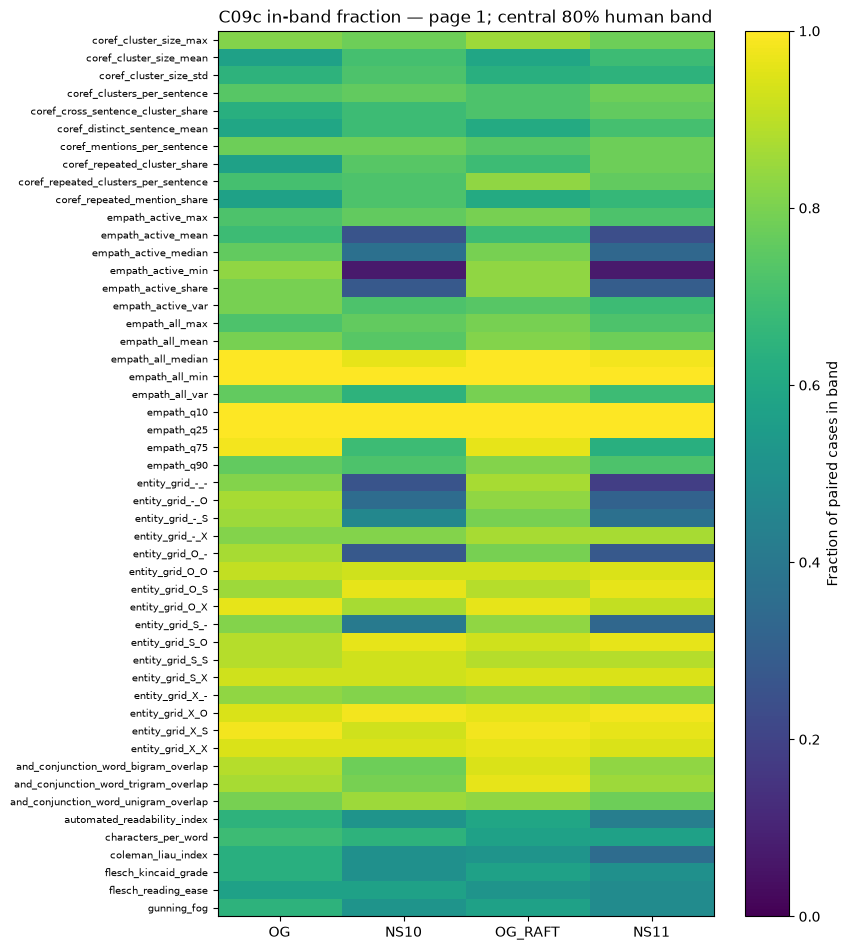

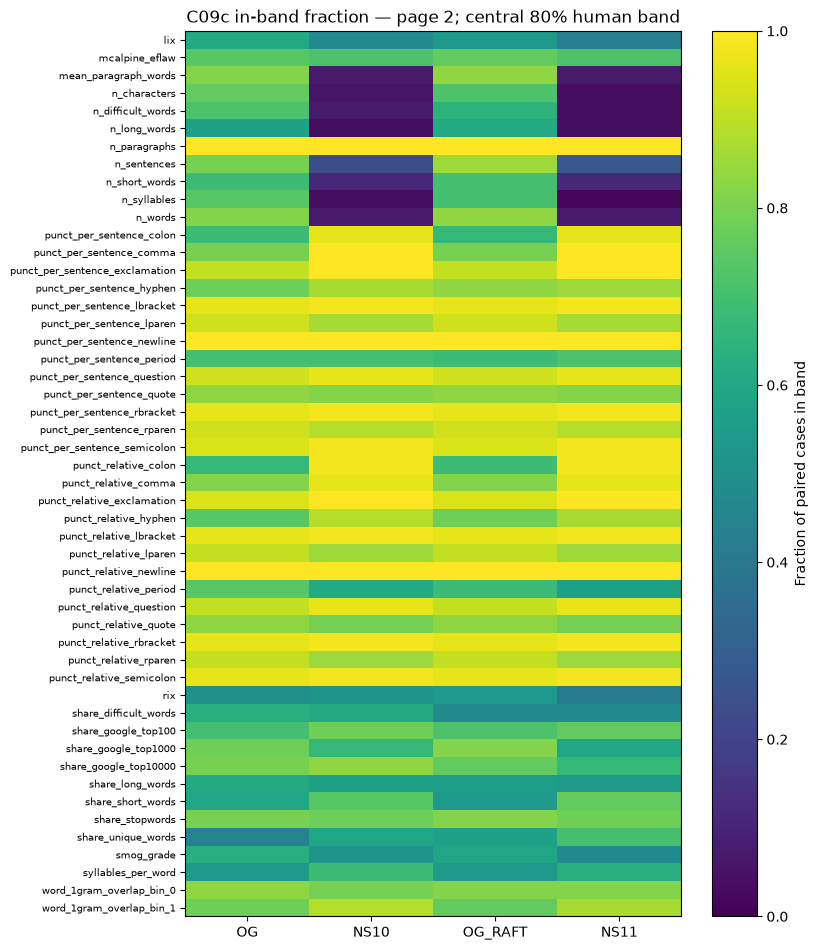

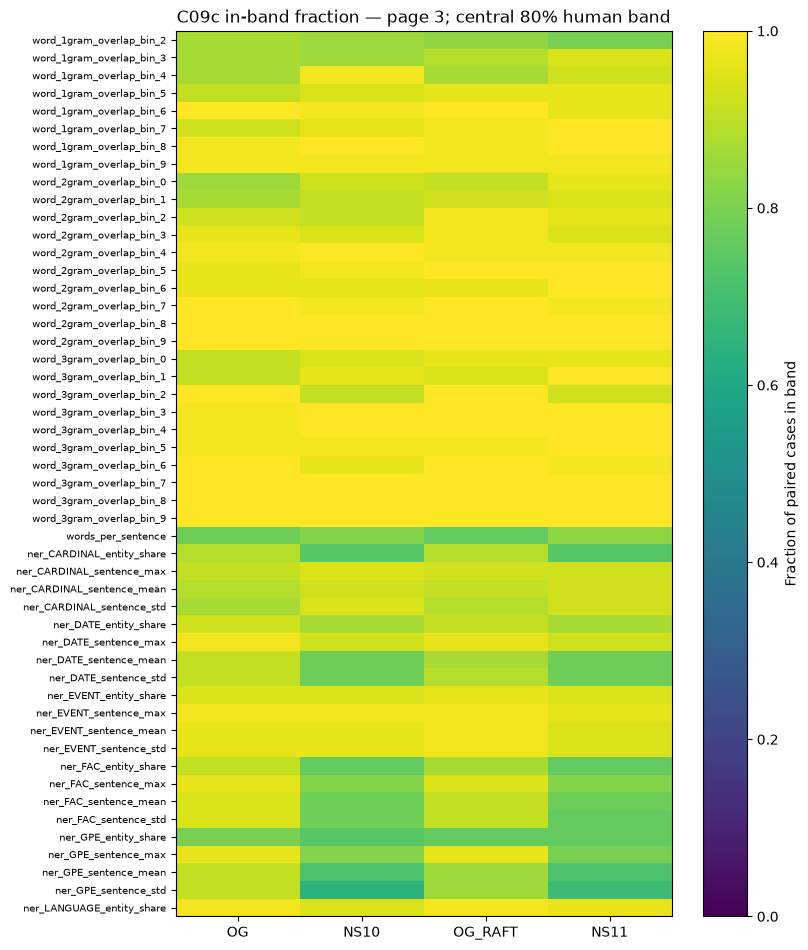

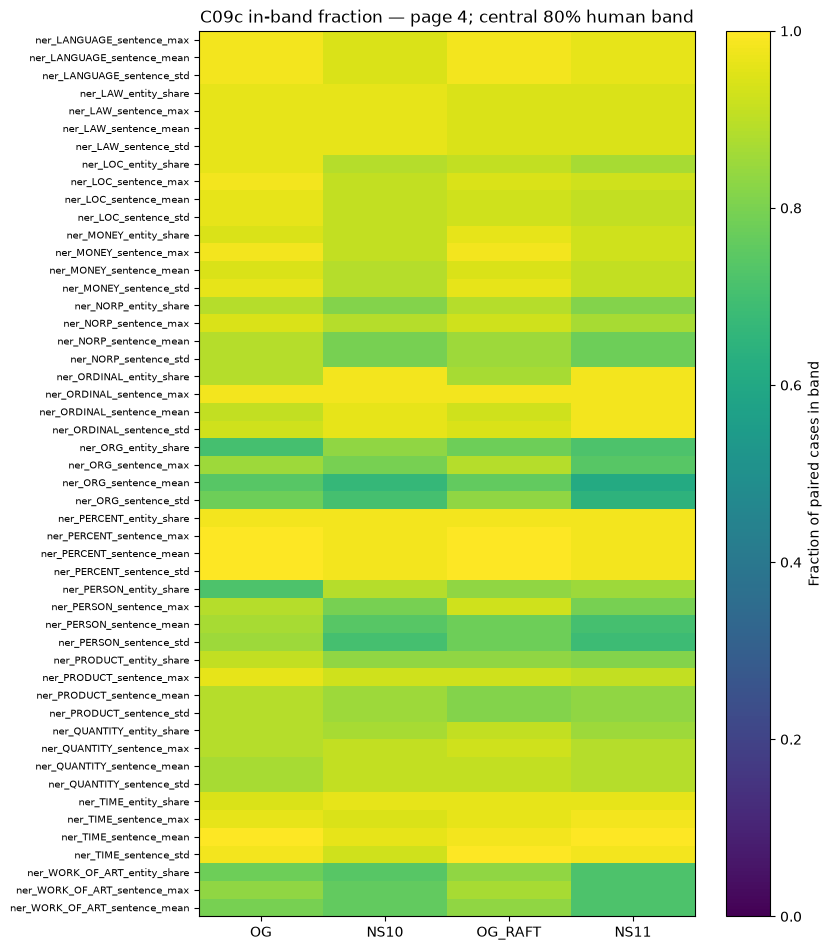

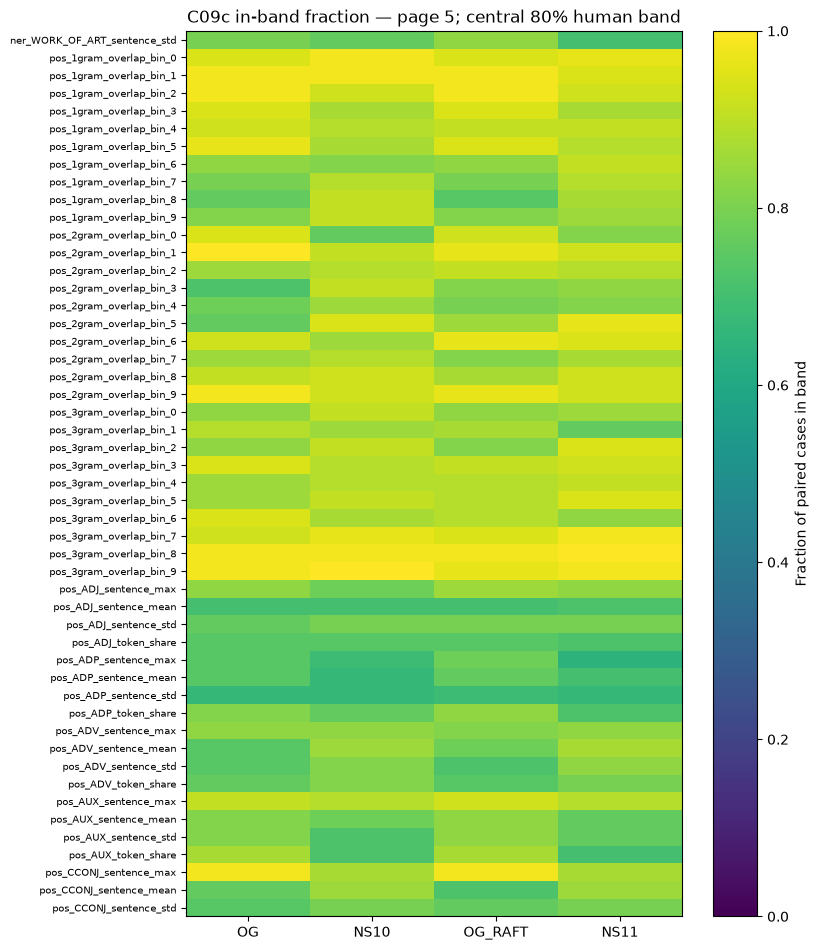

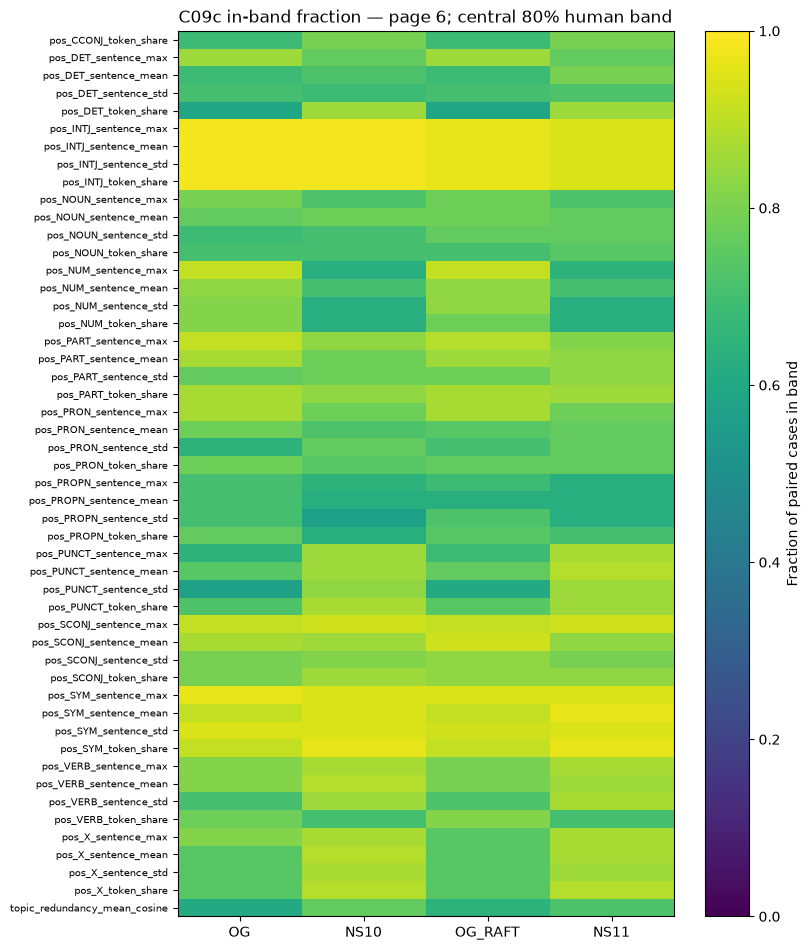

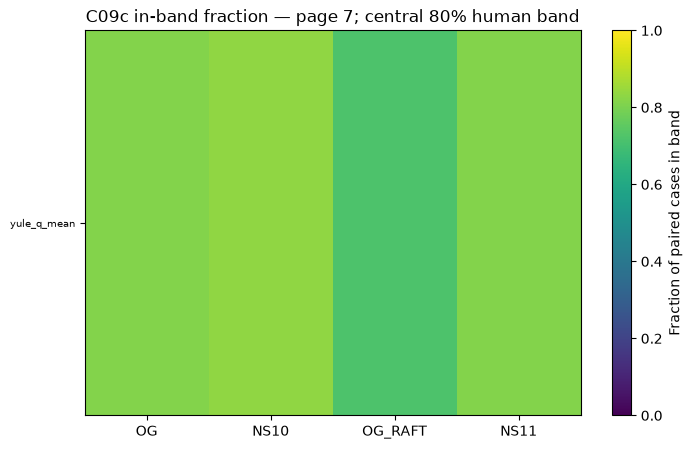

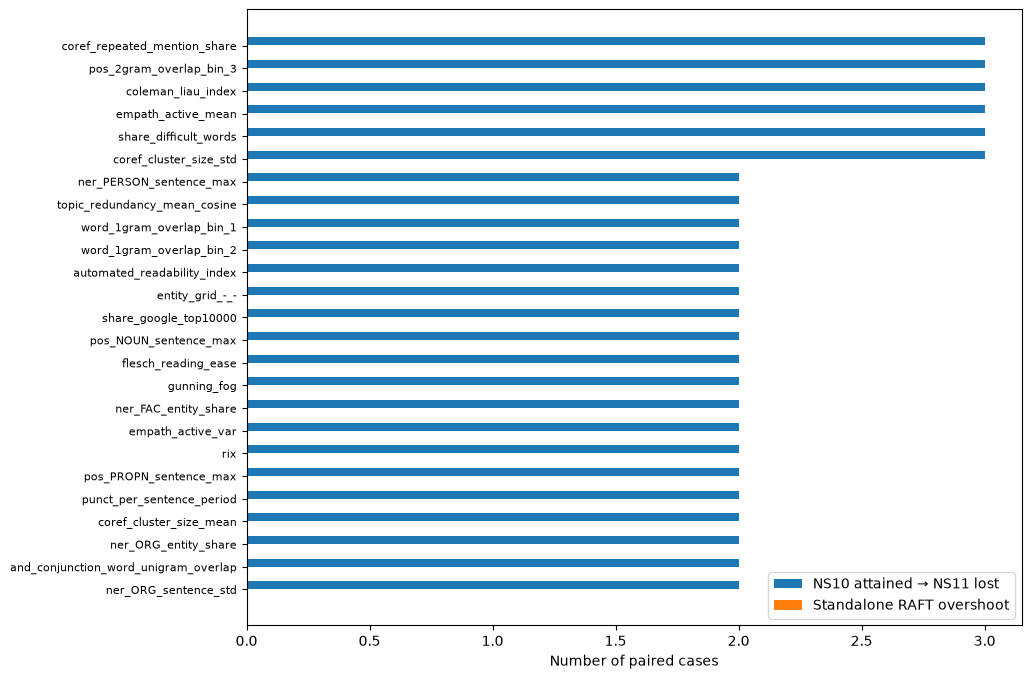

In [6]:
rng=np.random.default_rng(SEED);changes=[]
for (mode,q,f),g in valid.groupby(['mode','q','feature']):
 for metric in ['inside','distance']:
  p=g.pivot(index='case_id',columns='arm',values=metric).astype(float).dropna()
  ix=rng.integers(0,len(p),(N_BOOT,len(p)))
  for before,after in [('OG','NS10'),('OG','OG_RAFT'),('NS10','NS11')]:
   d=(p[after]-p[before]).to_numpy();lo,hi=np.quantile(d[ix].mean(axis=1),[.025,.975])
   changes.append(dict(mode=mode,q=q,feature=f,metric=metric,comparison=after+' minus '+before,n=len(d),delta=d.mean(),ci_low=lo,ci_high=hi))
changes=pd.DataFrame(changes);save(changes,'paired_changes.csv')
colors=['#888888','#219e83','#e7a529','#5943a8']
def finish(fig,name):
 fig.savefig(OUT/(name+'.png'),dpi=170,bbox_inches='tight');fig.savefig(OUT/(name+'.pdf'),bbox_inches='tight');plt.show();plt.close(fig)
primary=summary.loc[summary['mode'].eq('length_matched')&summary.q.eq(.1)]
# Paginate to keep all 301 feature labels readable.
order=catalog.sort_values(['family','feature']).feature.tolist()
for page,start in enumerate(range(0,len(order),50),1):
 fs=order[start:start+50];p=primary.pivot(index='feature',columns='arm',values='in_band_rate').reindex(index=fs,columns=ARMS)
 fig,ax=plt.subplots(figsize=(8,max(5,len(fs)*.23)))
 imshow=ax.imshow(np.ma.masked_invalid(p.to_numpy(float)),aspect='auto',vmin=0,vmax=1,cmap='viridis')
 ax.set_yticks(range(len(fs)),fs,fontsize=7);ax.set_xticks(range(4),ARMS);ax.set_title(f'C09c in-band fraction — page {page}; central 80% human band')
 fig.colorbar(imshow,ax=ax,label='Fraction of paired cases in band');finish(fig,f'attainment_page_{page}')
c=counts.loc[counts['mode'].eq('length_matched')&counts.q.eq(.1)].sort_values('NS10_attained_then_lost',ascending=False).head(25)
fig,ax=plt.subplots(figsize=(10,8));y=np.arange(len(c));ax.barh(y-.18,c.NS10_attained_then_lost,.35,label='NS10 attained → NS11 lost');ax.barh(y+.18,c.RAFT_AI_to_human_side_overshoot,.35,label='Standalone RAFT overshoot');ax.set_yticks(y,c.feature,fontsize=8);ax.invert_yaxis();ax.set_xlabel('Number of paired cases');ax.legend();finish(fig,'transition_counts_top25')


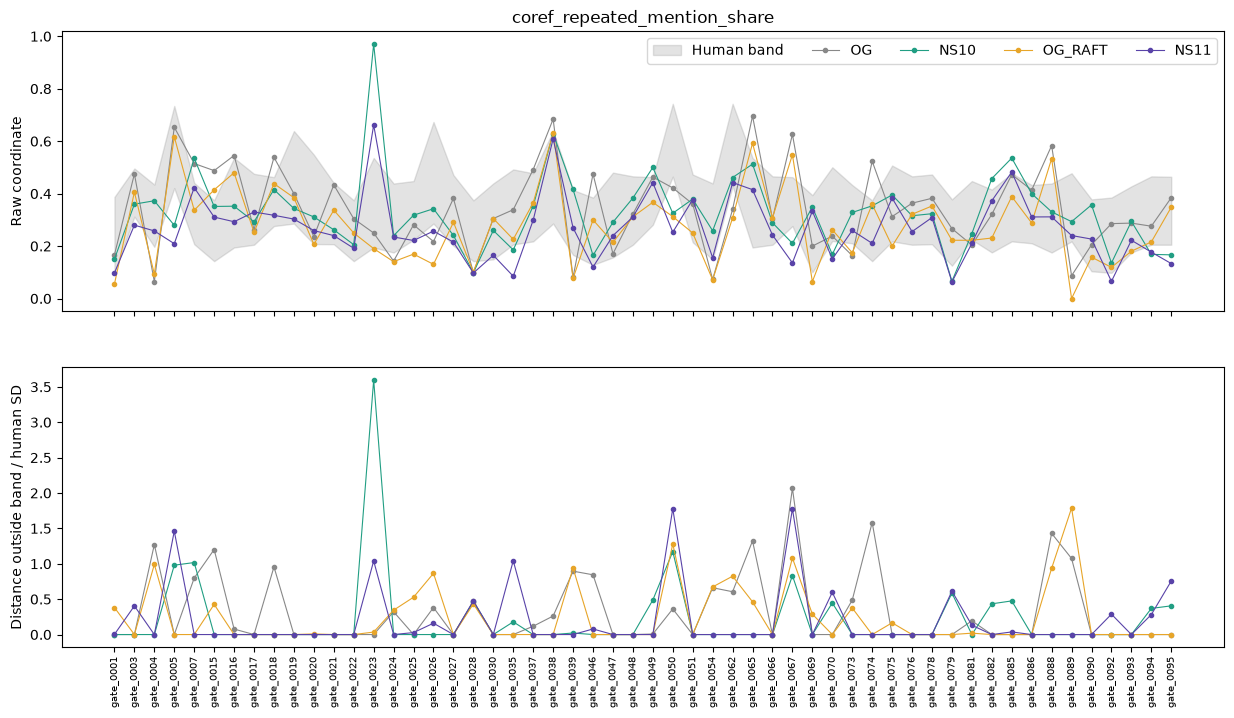

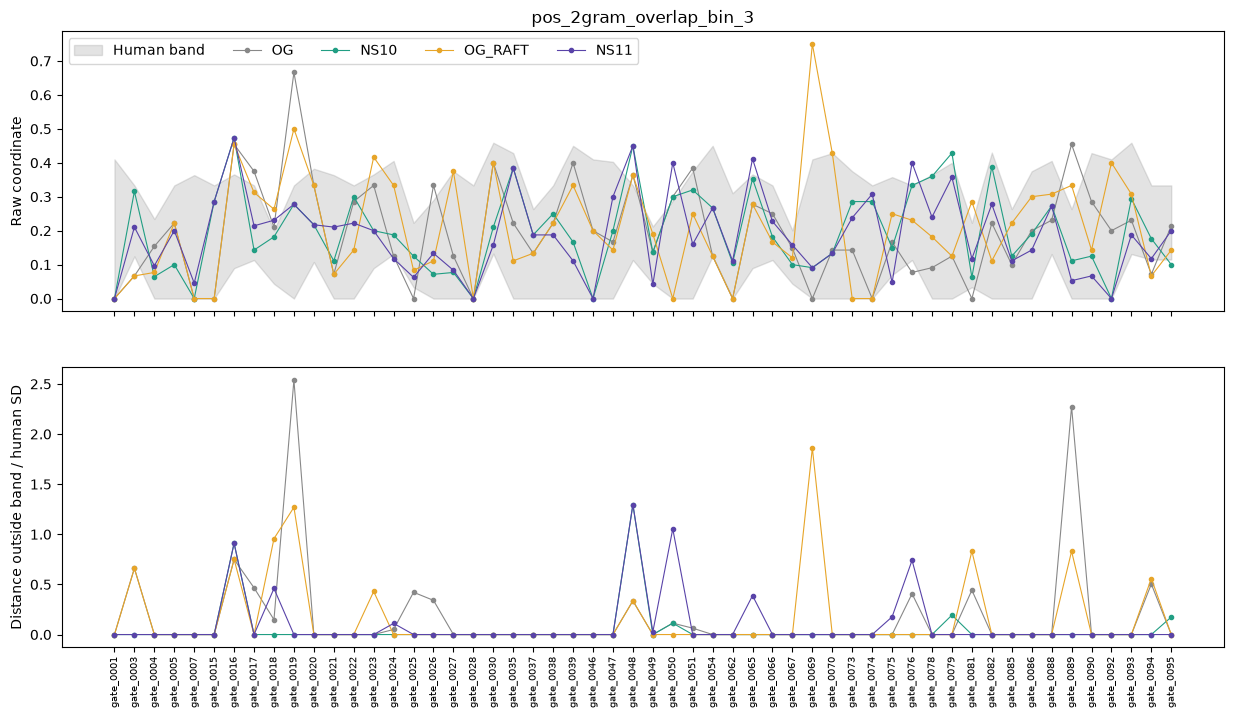

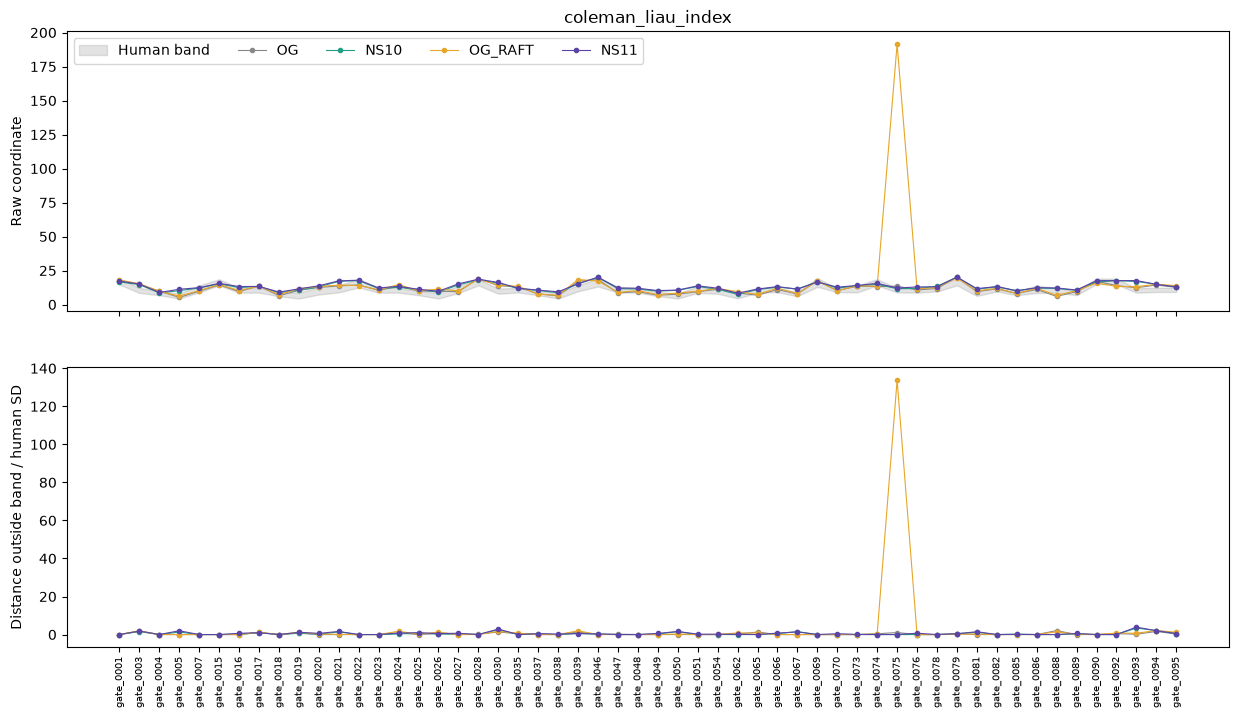

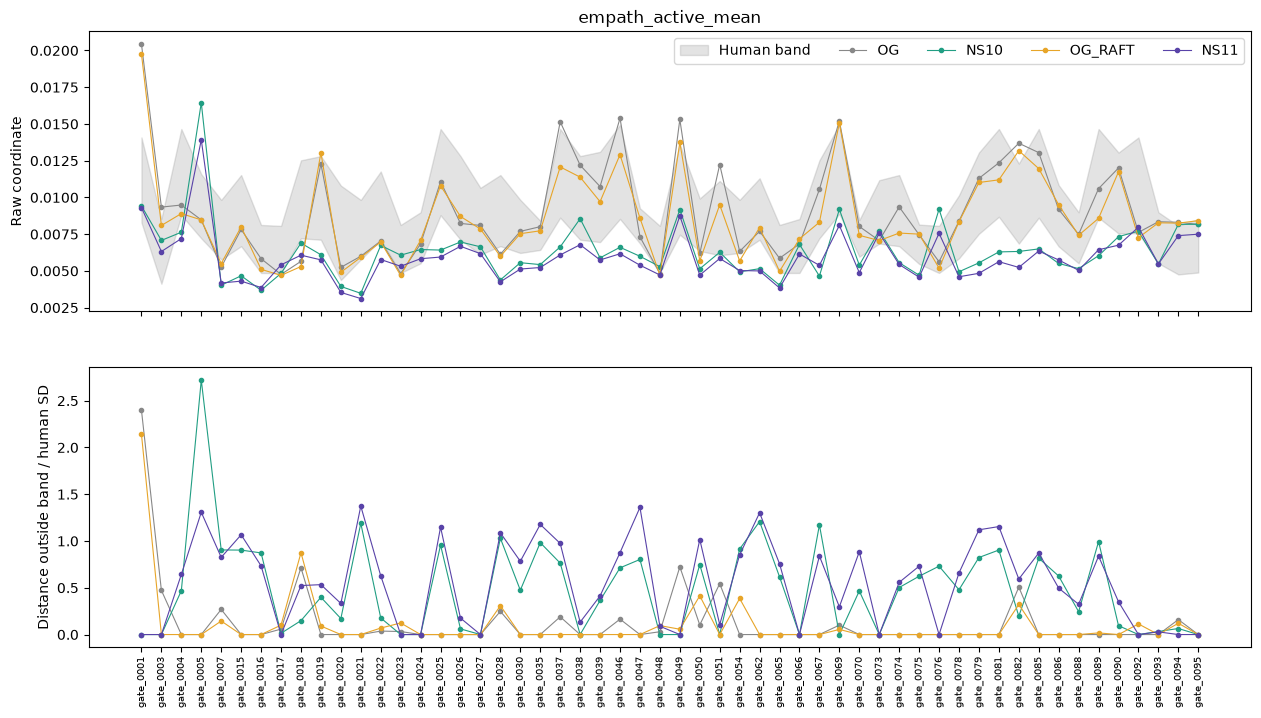

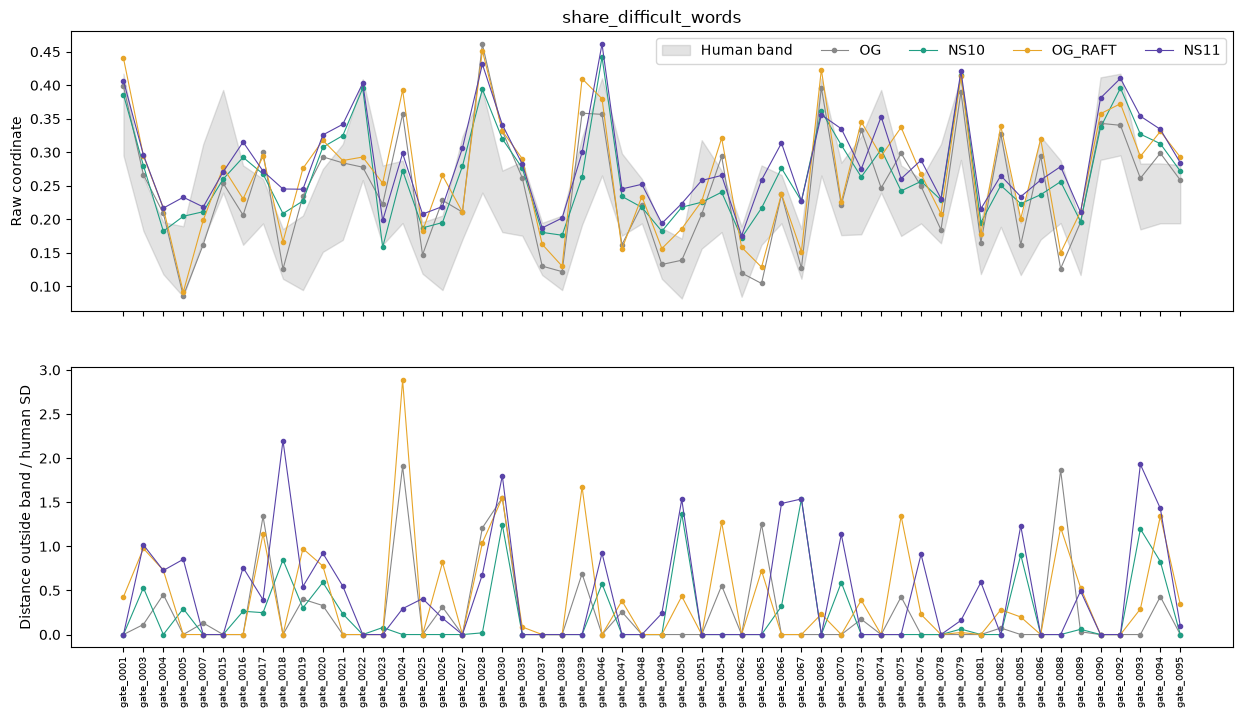

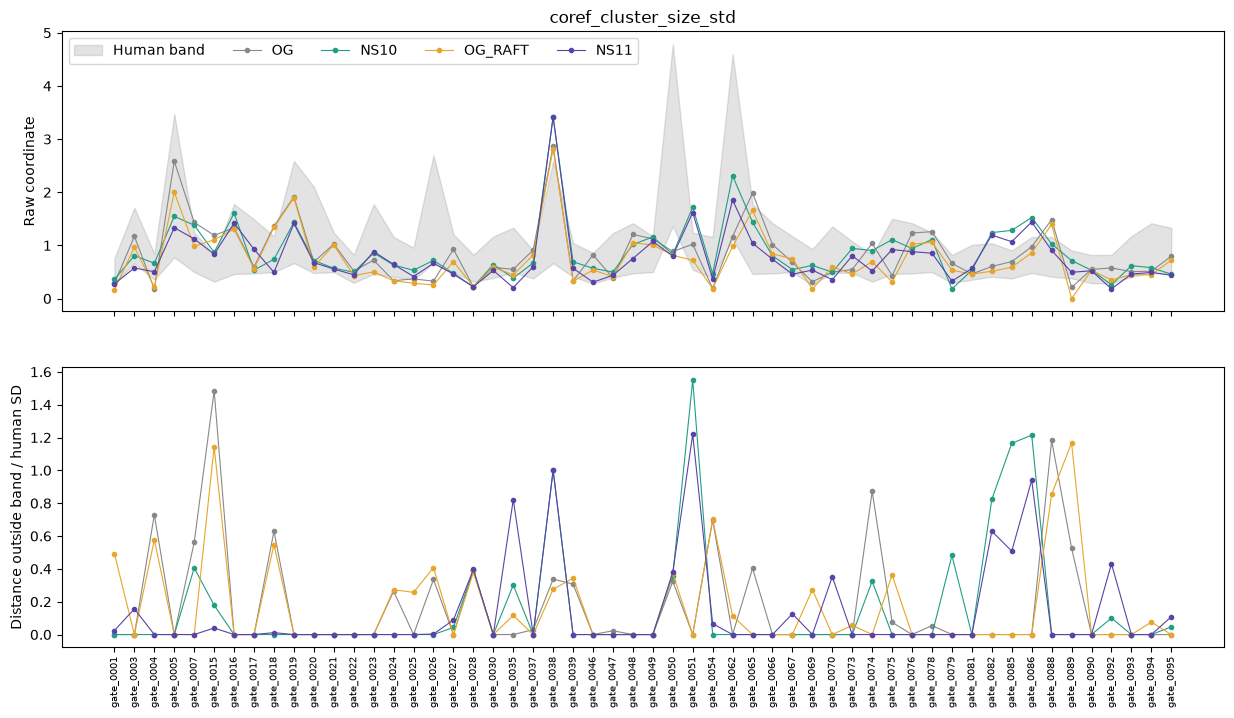

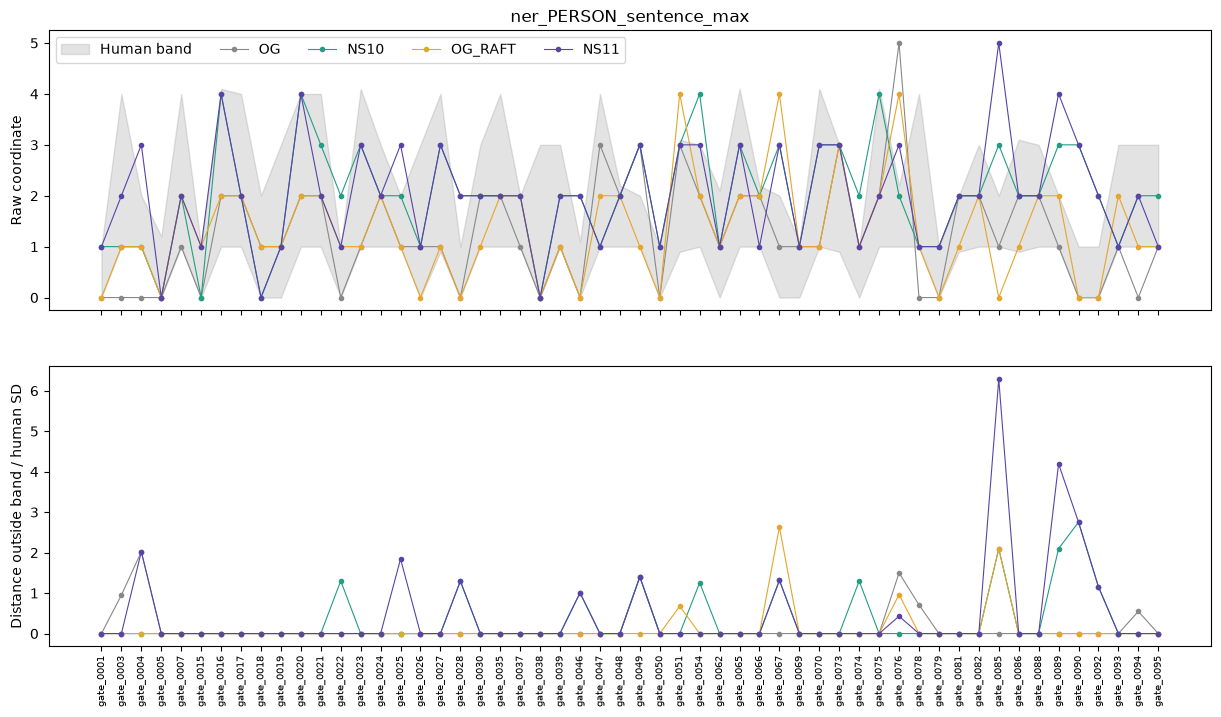

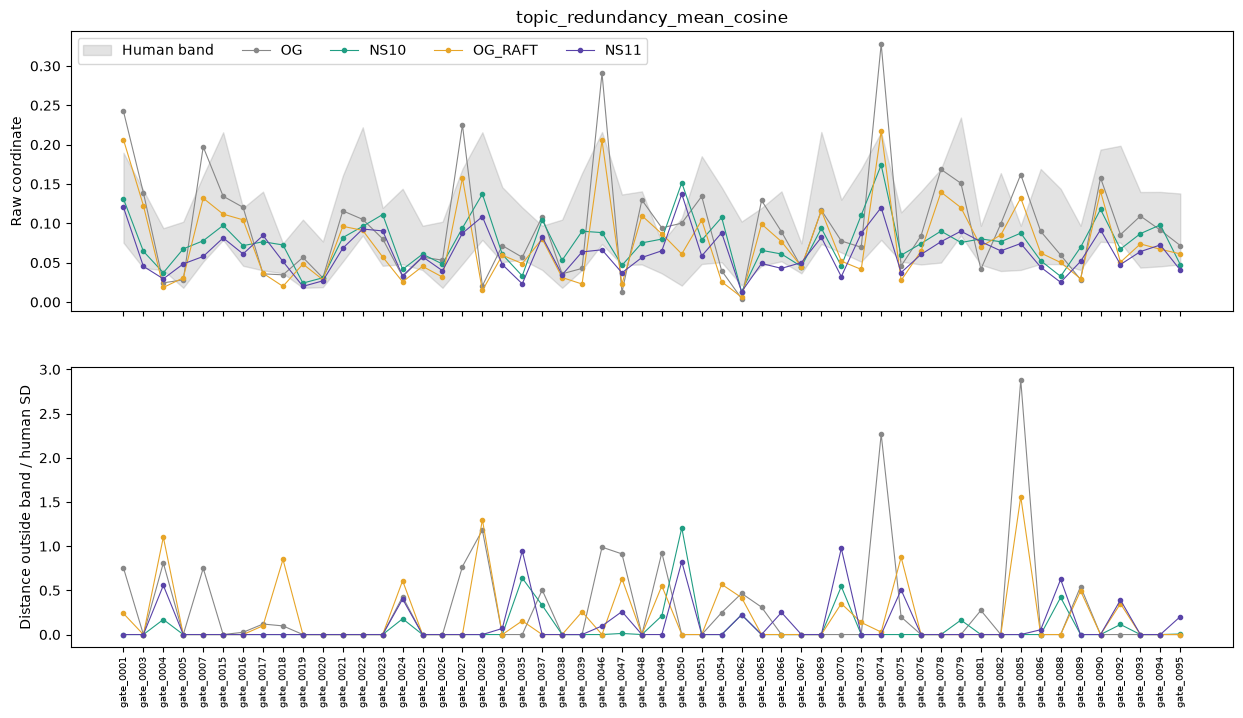

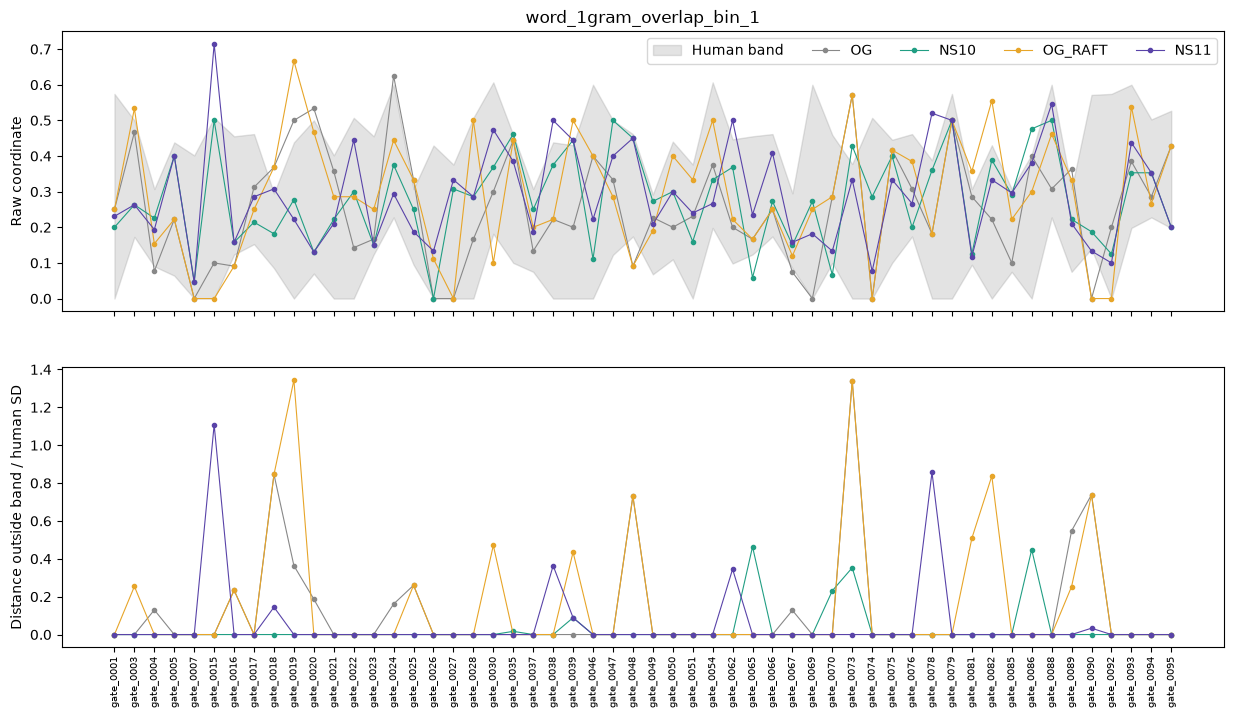

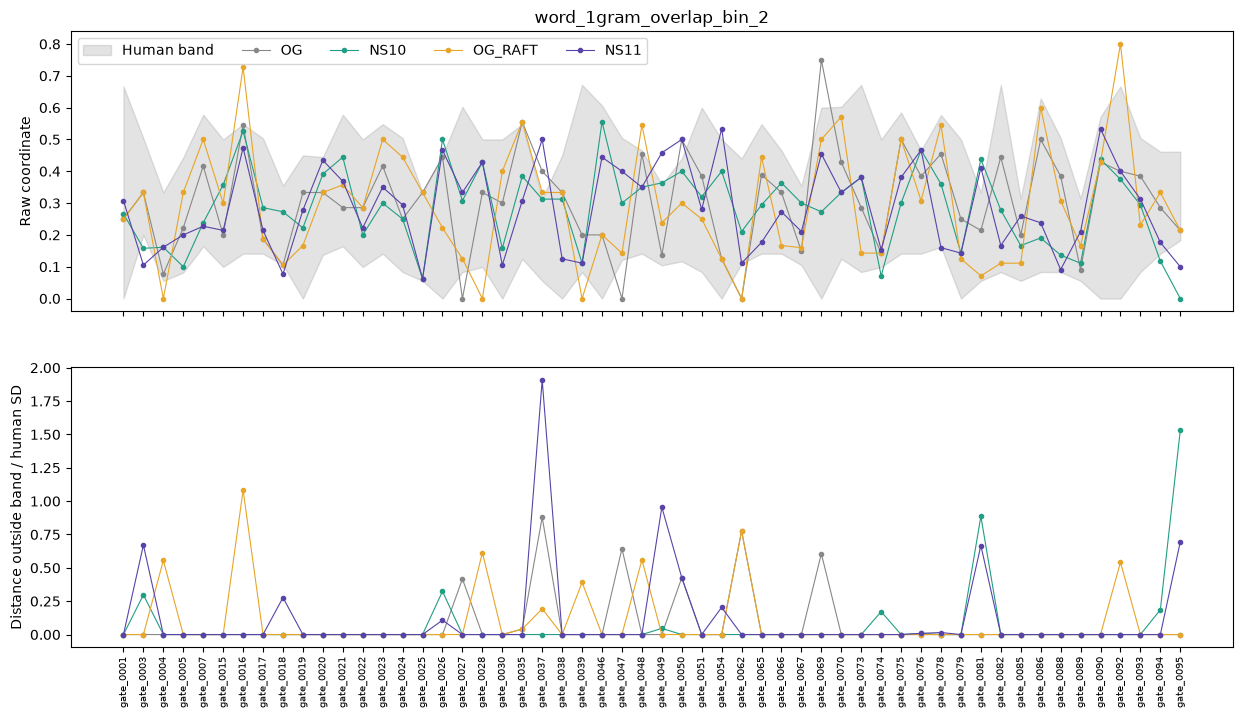

Saved C09c tables and figures to ../results/causal/C09c_FZ301_band_attainment_v1


In [7]:
# All four arms on each plot. Change FEATURE to inspect any of the 301 coordinates.
FEATURE=counts.loc[counts['mode'].eq('length_matched')&counts.q.eq(.1)].sort_values('NS10_attained_then_lost',ascending=False).feature.iloc[0]
def plot_coordinate(feature,mode='length_matched',q=.1):
 z=valid.loc[valid.feature.eq(feature)&valid['mode'].eq(mode)&valid.q.eq(q)]
 ids=sorted(z.case_id.unique());b=bands.loc[bands.feature.eq(feature)&bands['mode'].eq(mode)&bands.q.eq(q)].set_index('case_id').loc[ids]
 fig,axs=plt.subplots(2,1,figsize=(15,8),sharex=True)
 axs[0].fill_between(range(len(ids)),b.low,b.high,color='grey',alpha=.22,label='Human band')
 for a,color in zip(ARMS,colors):
  f=z.loc[z.arm.eq(a)].set_index('case_id').loc[ids]
  axs[0].plot(range(len(ids)),f.value,'o-',ms=3,lw=.8,color=color,label=a)
  axs[1].plot(range(len(ids)),f.distance,'o-',ms=3,lw=.8,color=color,label=a)
 axs[0].set_ylabel('Raw coordinate');axs[0].set_title(feature);axs[0].legend(ncol=5)
 axs[1].set_ylabel('Distance outside band / human SD');axs[1].set_xticks(range(len(ids)),ids,rotation=90,fontsize=7)
 finish(fig,'coordinate_'+feature)
plot_coordinate(FEATURE)
# Save detailed plots for the 10 largest attained-then-lost counts.
for f in c.feature.head(10):
 if f!=FEATURE:plot_coordinate(f)
print('Saved C09c tables and figures to',OUT)


### Reading the output
`paired_events.csv` provides each case/coordinate transition; `transition_counts_and_conditional_rates.csv` includes denominators, so loss on 1 of 1 eligible cases is distinguishable from loss on 40 of 50. `coordinate_long.parquet` retains all raw values, bounds, direction, zero-width flags and reference counts. Missing/sparse coordinates remain visible in `bands.csv` and heatmaps.

Overshoot here requires an OG coordinate on the training-AI side crossing beyond the opposite band boundary. Unoriented crossings are reported separately. Both disruption and independent overshoot may occur in the same case. A descriptive association with C09b recovery would need additional analysis; this notebook does not equate feature movement with a proven detector mechanism.

All eligible case-coordinate pairs; coordinates are correlated.


,transition,eligible_case_coordinates,gained,preserved,lost,remained_outside,before_in_band_pct,after_in_band_pct,net_attainment_pp,loss_given_inside_pct,gain_given_outside_pct
0,OG → NS10,16254,1543,11625,2138,948,84.675,81.014,-3.661,15.534,61.943
1,OG → OG_RAFT,16254,472,13321,442,2019,84.675,84.859,0.185,3.212,18.948
2,NS10 → NS11,16254,394,12707,461,2692,81.014,80.602,-0.412,3.501,12.767


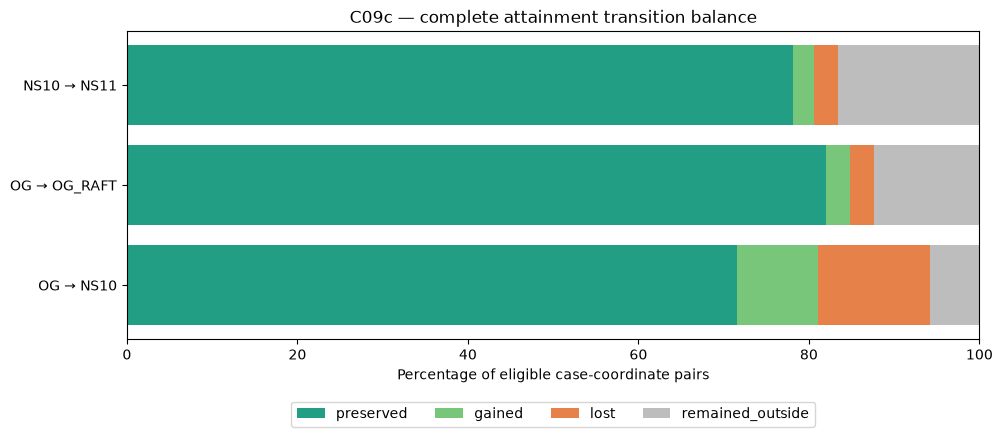


Standalone RAFT overshoot — independently ranked:


,feature,RAFT_overshoot,OG_AI_side_eligible,RAFT_opposite_boundary_crossing,RAFT_inside_then_lost,OG_inside_eligible,NS10_attained,NS10_attained_then_lost,NS11_overshoot_after_attainment,NS11_reversal_after_attainment,eligible_cases,RAFT_overshoot_given_AI_side_pct,RAFT_loss_given_inside_pct
30,empath_q90,0,8,1,1,41,9,1,0,1,54,0.0,2.439
146,pos_2gram_overlap_bin_3,0,10,1,2,39,12,3,1,2,54,0.0,5.128
0,and_conjunction_word_bigram_overlap,0,0,0,1,48,3,0,0,0,54,NaN,2.083
1,and_conjunction_word_trigram_overlap,0,0,0,0,47,4,0,0,0,54,NaN,0.000
2,and_conjunction_word_unigram_overlap,0,6,0,0,43,9,2,0,0,54,0.0,0.000
3,automated_readability_index,0,14,0,3,35,6,2,0,1,54,0.0,8.571
4,characters_per_word,0,11,0,6,37,6,1,0,0,54,0.0,16.216
5,coleman_liau_index,0,14,0,7,34,9,3,0,1,54,0.0,20.588
6,coref_cluster_size_max,0,3,0,0,44,7,1,0,0,54,0.0,0.000
7,coref_cluster_size_mean,0,13,0,6,31,17,2,0,1,54,0.0,19.355


Overshoot occurs in 0 case-coordinate pairs across 0 features.


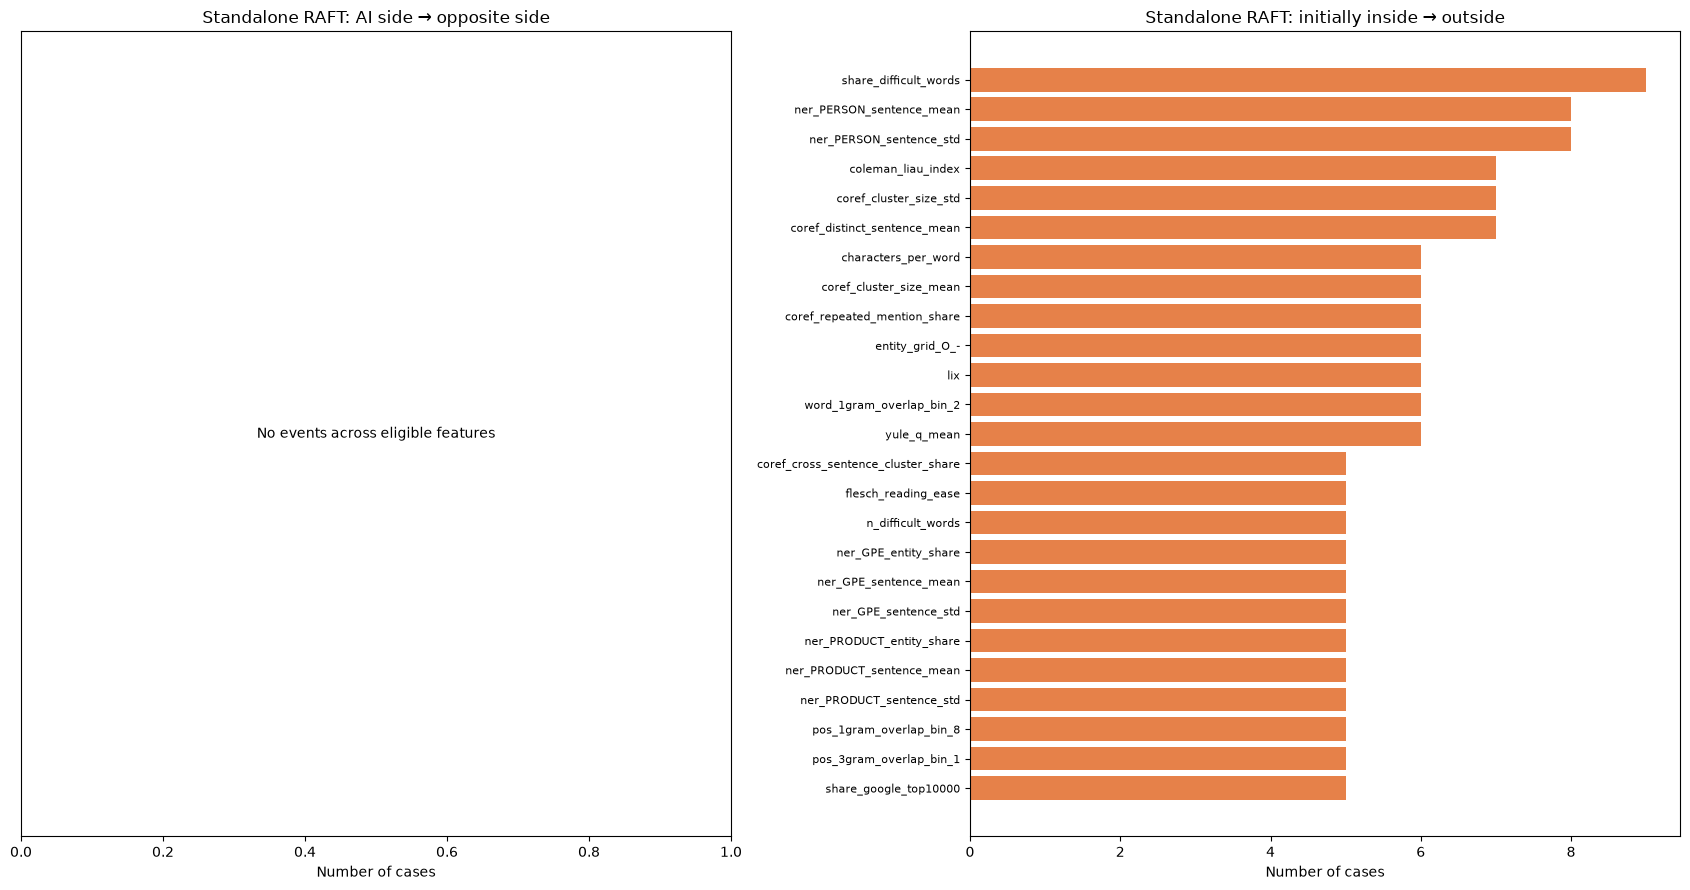


Largest net attainment losses under composition:


,feature,gained,preserved,lost,remained_outside,eligible_cases,before_inside,after_inside,net_attainment_pp,transition
863,share_google_top10000,1,35,10,8,54,45,36,-16.667,NS10 → NS11
607,coleman_liau_index,0,19,8,27,54,27,19,-14.815,NS10 → NS11
860,share_difficult_words,1,25,8,20,54,33,26,-12.963,NS10 → NS11
859,rix,0,22,6,26,54,28,22,-11.111,NS10 → NS11
707,ner_ORG_entity_share,1,38,7,8,54,45,39,-11.111,NS10 → NS11
756,pos_3gram_overlap_bin_1,2,39,7,6,54,46,41,-9.259,NS10 → NS11
650,flesch_reading_ease,0,26,5,23,54,31,26,-9.259,NS10 → NS11
635,entity_grid_-_S,1,19,6,28,54,25,20,-9.259,NS10 → NS11
605,automated_readability_index,0,23,5,26,54,28,23,-9.259,NS10 → NS11
748,pos_2gram_overlap_bin_3,2,43,6,3,54,49,45,-7.407,NS10 → NS11



Largest net attainment gains under composition:


,feature,gained,preserved,lost,remained_outside,eligible_cases,before_inside,after_inside,net_attainment_pp,transition
867,share_unique_words,7,31,1,15,54,32,38,11.111,NS10 → NS11
874,word_1gram_overlap_bin_3,6,45,1,2,54,46,51,9.259,NS10 → NS11
751,pos_2gram_overlap_bin_6,6,45,1,2,54,46,51,9.259,NS10 → NS11
741,pos_1gram_overlap_bin_6,6,43,1,4,54,44,49,9.259,NS10 → NS11
786,pos_DET_sentence_mean,4,39,0,11,54,39,43,7.407,NS10 → NS11
612,coref_cross_sentence_cluster_share,5,36,1,12,54,37,41,7.407,NS10 → NS11
812,pos_PROPN_token_share,5,33,1,15,54,34,38,7.407,NS10 → NS11
811,pos_PROPN_sentence_std,5,29,2,18,54,31,34,5.556,NS10 → NS11
802,pos_PART_sentence_mean,3,42,0,9,54,42,45,5.556,NS10 → NS11
765,pos_ADJ_sentence_max,3,42,0,9,54,42,45,5.556,NS10 → NS11



Cases with both standalone RAFT overshoot and loss of NS10 attainment (possibly on different coordinates): 0/54
Saved follow-up tables and figures to: ../results/causal/C09c_FZ301_band_attainment_v1


In [8]:
# C09c follow-up: attainment balance + independent RAFT overshoot ranking
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# OUT is already defined in C09c. This also works after rerunning setup only.
MODE, Q, TOP = "length_matched", 0.10, 25

z = pd.read_parquet(OUT / "coordinate_long.parquet")
z = z.loc[
    z["mode"].eq(MODE)
    & np.isclose(z["q"], Q)
    & z["valid"].eq(True)
].copy()

arms = ["OG", "NS10", "OG_RAFT", "NS11"]
states = z.pivot(
    index=["case_id", "feature"], columns="arm", values="state"
).reindex(columns=arms)
oriented = z.pivot(
    index=["case_id", "feature"], columns="arm", values="oriented_state"
).reindex(columns=arms)

assert states.notna().all().all(), "Incomplete four-arm feature pairs."
assert not states.empty, "No eligible coordinates for this reference setting."

def save_plot(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

# 1. Complete transition accounting, including already-outside coordinates.
pairs = [
    ("OG", "NS10"),
    ("OG", "OG_RAFT"),
    ("NS10", "NS11"),
]
balances, feature_balances = [], []

for before, after in pairs:
    b, a = states[before], states[after]
    t = pd.DataFrame({
        "gained": b.ne(0) & a.eq(0),
        "preserved": b.eq(0) & a.eq(0),
        "lost": b.eq(0) & a.ne(0),
        "remained_outside": b.ne(0) & a.ne(0),
    })
    assert t.sum(axis=1).eq(1).all()

    n = len(t)
    nb, na = int(b.eq(0).sum()), int(a.eq(0).sum())
    totals = t.sum().astype(int)
    balances.append({
        "transition": f"{before} → {after}",
        "eligible_case_coordinates": n,
        **totals.to_dict(),
        "before_in_band_pct": 100 * nb / n,
        "after_in_band_pct": 100 * na / n,
        "net_attainment_pp": 100 * (na - nb) / n,
        "loss_given_inside_pct":
            100 * totals["lost"] / nb if nb else np.nan,
        "gain_given_outside_pct":
            100 * totals["gained"] / (n - nb) if n > nb else np.nan,
    })

    ft = t.groupby(level="feature").sum().astype(int)
    ft["eligible_cases"] = t.groupby(level="feature").size()
    ft["before_inside"] = b.eq(0).groupby(level="feature").sum()
    ft["after_inside"] = a.eq(0).groupby(level="feature").sum()
    ft["net_attainment_pp"] = (
        100 * (ft.after_inside - ft.before_inside) / ft.eligible_cases
    )
    ft["transition"] = f"{before} → {after}"
    feature_balances.append(ft.reset_index())

balance = pd.DataFrame(balances)
feature_balance = pd.concat(feature_balances, ignore_index=True)
balance.to_csv(OUT / "followup_attainment_balance.csv", index=False)
feature_balance.to_csv(
    OUT / "followup_feature_attainment_balance.csv", index=False
)

print("All eligible case-coordinate pairs; coordinates are correlated.")
display(balance.round(3))

fig, ax = plt.subplots(figsize=(11, 4))
left = np.zeros(len(balance))
for name, color in [
    ("preserved", "#219e83"),
    ("gained", "#78c679"),
    ("lost", "#e68149"),
    ("remained_outside", "#bdbdbd"),
]:
    pct = 100 * balance[name] / balance.eligible_case_coordinates
    ax.barh(balance.transition, pct, left=left, label=name, color=color)
    left += pct.to_numpy()
ax.set(xlabel="Percentage of eligible case-coordinate pairs", xlim=(0, 100))
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.set_title("C09c — complete attainment transition balance")
save_plot(fig, "followup_attainment_balance")

# 2. Independent overshoot analysis across ALL eligible features.
ev = pd.DataFrame(index=states.index)
ev["RAFT_overshoot"] = (
    oriented["OG"].eq(1) & oriented["OG_RAFT"].eq(-1)
)
ev["OG_AI_side_eligible"] = oriented["OG"].eq(1)
ev["RAFT_opposite_boundary_crossing"] = (
    states["OG"] * states["OG_RAFT"]
).eq(-1)
ev["RAFT_inside_then_lost"] = (
    states["OG"].eq(0) & states["OG_RAFT"].ne(0)
)
ev["OG_inside_eligible"] = states["OG"].eq(0)
ev["NS10_attained"] = states["OG"].ne(0) & states["NS10"].eq(0)
ev["NS10_attained_then_lost"] = (
    ev["NS10_attained"] & states["NS11"].ne(0)
)
ev["NS11_overshoot_after_attainment"] = (
    oriented["OG"].eq(1)
    & states["NS10"].eq(0)
    & oriented["NS11"].eq(-1)
)
ev["NS11_reversal_after_attainment"] = (
    oriented["OG"].eq(1)
    & states["NS10"].eq(0)
    & oriented["NS11"].eq(1)
)

rank = ev.groupby(level="feature").sum().astype(int)
rank["eligible_cases"] = ev.groupby(level="feature").size()
rank["RAFT_overshoot_given_AI_side_pct"] = (
    100 * rank.RAFT_overshoot
    / rank.OG_AI_side_eligible.replace(0, np.nan)
)
rank["RAFT_loss_given_inside_pct"] = (
    100 * rank.RAFT_inside_then_lost
    / rank.OG_inside_eligible.replace(0, np.nan)
)
rank = rank.reset_index().sort_values(
    ["RAFT_overshoot", "RAFT_opposite_boundary_crossing", "feature"],
    ascending=[False, False, True],
)
rank.to_csv(OUT / "followup_RAFT_overshoot_all_features.csv", index=False)

print("\nStandalone RAFT overshoot — independently ranked:")
display(rank.head(TOP).round(3))
print(
    f"Overshoot occurs in {int(rank.RAFT_overshoot.sum())} case-coordinate "
    f"pairs across {int(rank.RAFT_overshoot.gt(0).sum())} features."
)

# Separate rankings avoid hiding one event by sorting on another.
fig, axes = plt.subplots(1, 2, figsize=(17, 9))
for ax, metric, title, color in [
    (axes[0], "RAFT_overshoot",
     "Standalone RAFT: AI side → opposite side", "#e7a529"),
    (axes[1], "RAFT_inside_then_lost",
     "Standalone RAFT: initially inside → outside", "#e68149"),
]:
    p = rank.loc[rank[metric].gt(0)].sort_values(
        [metric, "feature"], ascending=[False, True]
    ).head(TOP)
    if p.empty:
        ax.text(
            0.5, 0.5, "No events across eligible features",
            ha="center", va="center", transform=ax.transAxes,
        )
        ax.set_yticks([])
    else:
        ax.barh(p.feature, p[metric], color=color)
        ax.invert_yaxis()
        ax.tick_params(axis="y", labelsize=8)
    ax.set_title(title)
    ax.set_xlabel("Number of cases")
fig.tight_layout()
save_plot(fig, "followup_RAFT_independent_rankings")

# 3. Which features improve or deteriorate most after composition?
composition = feature_balance.loc[
    feature_balance.transition.eq("NS10 → NS11")
].copy()

print("\nLargest net attainment losses under composition:")
display(composition.sort_values("net_attainment_pp").head(15).round(3))
print("\nLargest net attainment gains under composition:")
display(
    composition.sort_values("net_attainment_pp", ascending=False)
    .head(15).round(3)
)

# 4. Do disruption and standalone overshoot coexist within the same text?
case = ev.groupby(level="case_id").sum().astype(int)
case["both_mechanisms_present"] = (
    case.RAFT_overshoot.gt(0) & case.NS10_attained_then_lost.gt(0)
)
case.reset_index().to_csv(
    OUT / "followup_case_mechanism_counts.csv", index=False
)
print(
    "\nCases with both standalone RAFT overshoot and loss of NS10 attainment "
    f"(possibly on different coordinates): "
    f"{int(case.both_mechanisms_present.sum())}/{len(case)}"
)
print("Saved follow-up tables and figures to:", OUT)

/tmp/ipykernel_63266/4092416482.py:69: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  human_x[name] = source.loc[hm.source_id, name].to_numpy(float)
/tmp/ipykernel_63266/4092416482.py:69: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  human_x[name] = source.loc[hm.source_id, name].to_numpy(float)
/tmp/ipykernel_63266/4092416482.py:69: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat

Frozen FZ301 scores; positive adjusted values mean more AI-directed:


,AI_score,human_adjusted_AI_score
arm,,
OG,0.59942,0.19470
NS10,0.44207,0.03735
OG_RAFT,0.57833,0.17361
NS11,0.42584,0.02112


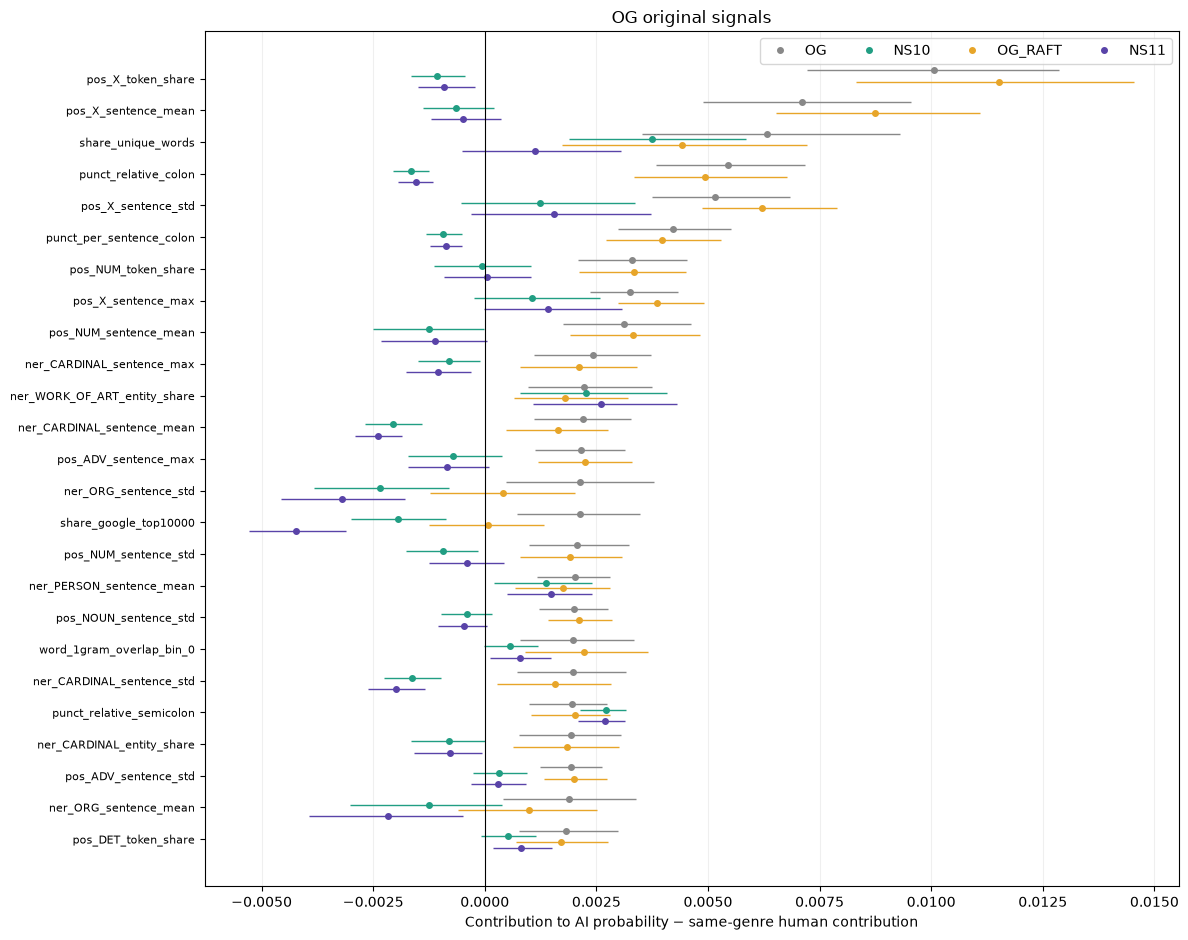

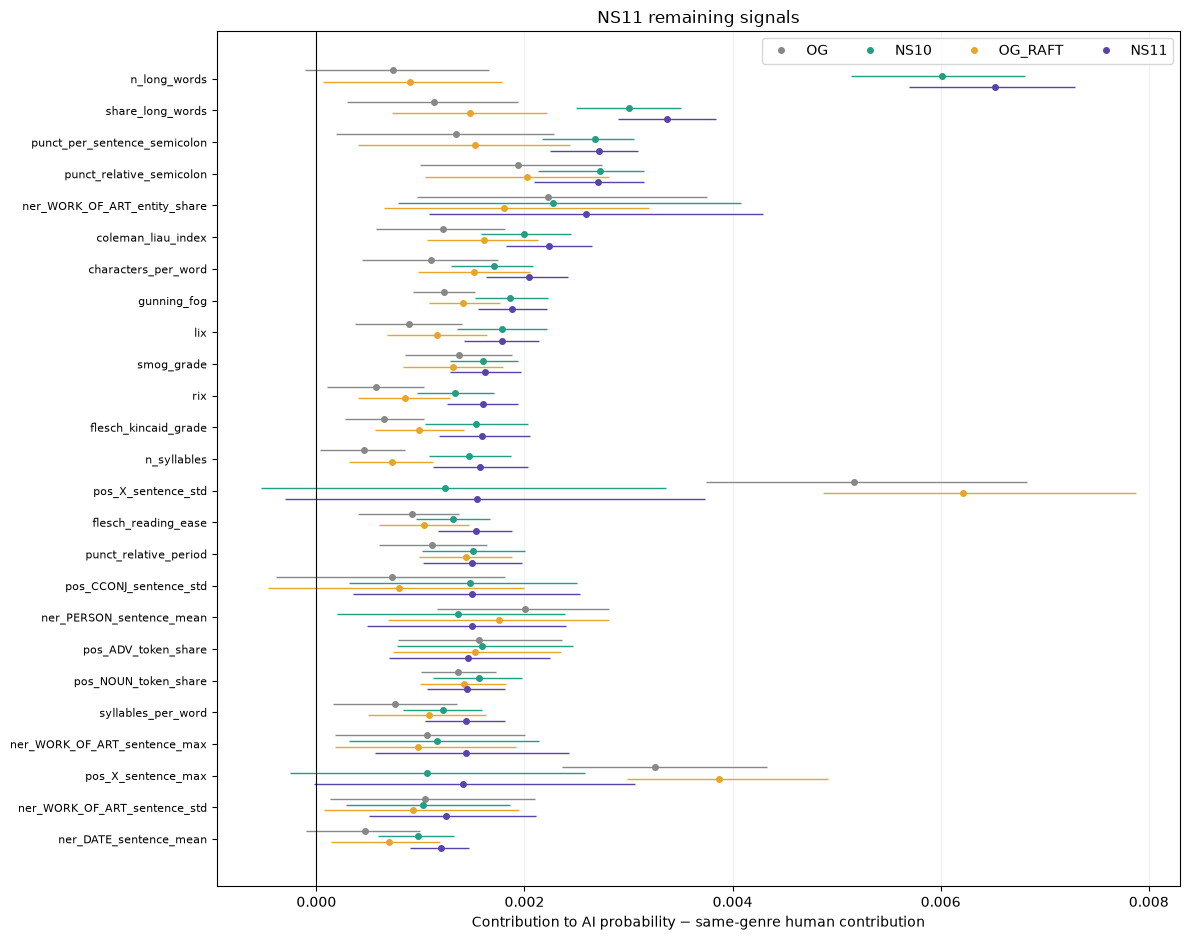

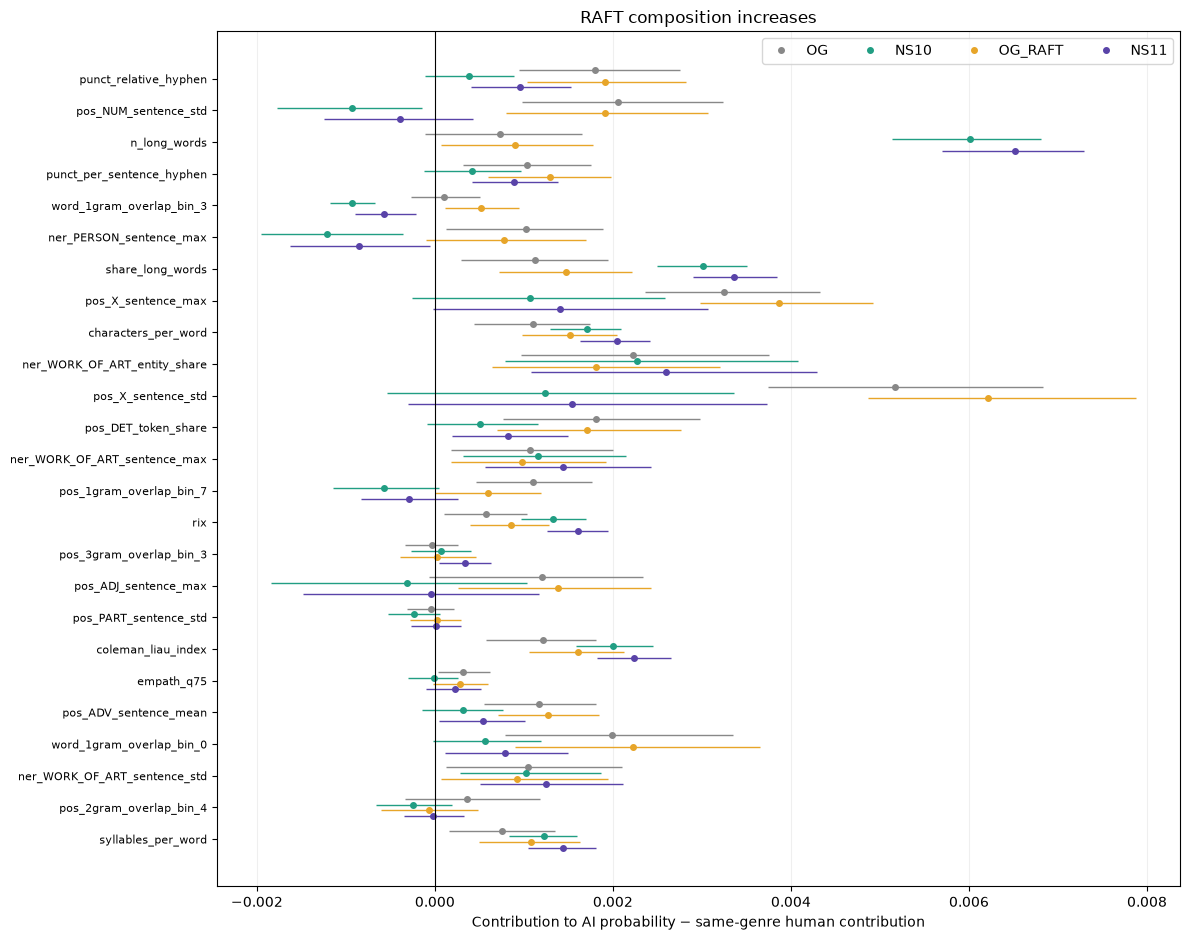


Largest AI-contribution increases after adding RAFT:


,feature,delta_NS11_minus_NS10,ci_low,ci_high,fraction_cases_increased
33,punct_relative_hyphen,0.000579,0.000328,0.000824,0.666667
152,pos_NUM_sentence_std,0.000535,0.000171,0.000901,0.648148
6,n_long_words,0.000511,0.000161,0.000858,0.703704
46,punct_per_sentence_hyphen,0.000466,0.000159,0.000833,0.574074
58,word_1gram_overlap_bin_3,0.000364,0.000048,0.000695,0.500000
241,ner_PERSON_sentence_max,0.000359,-0.000204,0.000932,0.518519
12,share_long_words,0.000359,0.000031,0.000721,0.629630
185,pos_X_sentence_max,0.000340,-0.000050,0.000847,0.500000
7,characters_per_word,0.000330,0.000026,0.000625,0.574074
254,ner_WORK_OF_ART_entity_share,0.000319,-0.000258,0.000928,0.518519


,delta_NS11_minus_NS10,ci_low,ci_high,fraction_cases_increased,NS10_attained_then_lost,NS10_inside_then_lost,complementary_attainment,eligible_NS10_inside,contribution_NS10,contribution_NS11,contribution_OG,contribution_OG_RAFT
feature,,,,,,,,,,,,
punct_relative_hyphen,0.00058,0.00033,0.00082,0.66667,0,1,0,48,0.00038,0.00096,0.00180,0.00191
pos_NUM_sentence_std,0.00053,0.00017,0.00090,0.64815,0,1,1,34,-0.00093,-0.00039,0.00206,0.00191
n_long_words,0.00051,0.00016,0.00086,0.70370,0,0,0,2,0.00601,0.00652,0.00074,0.00090
punct_per_sentence_hyphen,0.00047,0.00016,0.00083,0.57407,1,2,1,47,0.00042,0.00089,0.00103,0.00129
word_1gram_overlap_bin_3,0.00036,0.00005,0.00070,0.50000,1,1,6,46,-0.00094,-0.00057,0.00011,0.00052
ner_PERSON_sentence_max,0.00036,-0.00020,0.00093,0.51852,2,3,3,43,-0.00121,-0.00085,0.00102,0.00078
share_long_words,0.00036,0.00003,0.00072,0.62963,0,3,1,31,0.00301,0.00337,0.00113,0.00147
pos_X_sentence_max,0.00034,-0.00005,0.00085,0.50000,0,0,0,47,0.00107,0.00141,0.00325,0.00387
characters_per_word,0.00033,0.00003,0.00063,0.57407,1,5,1,35,0.00171,0.00204,0.00110,0.00152


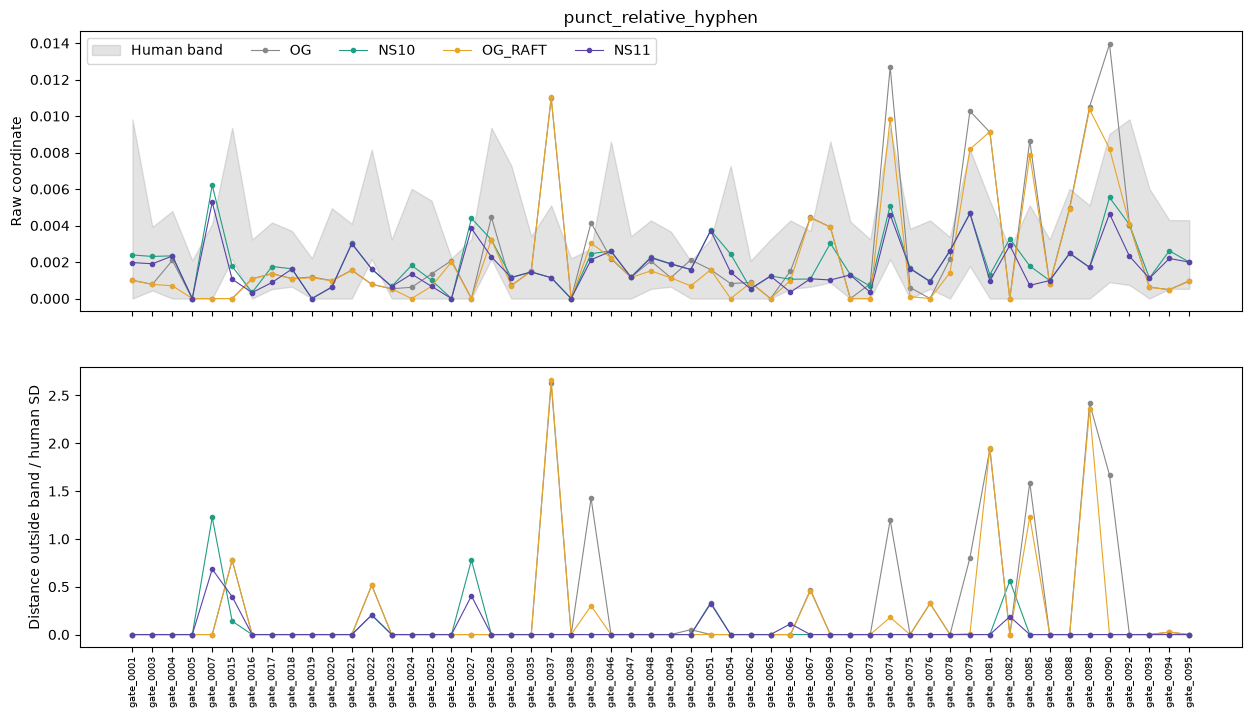

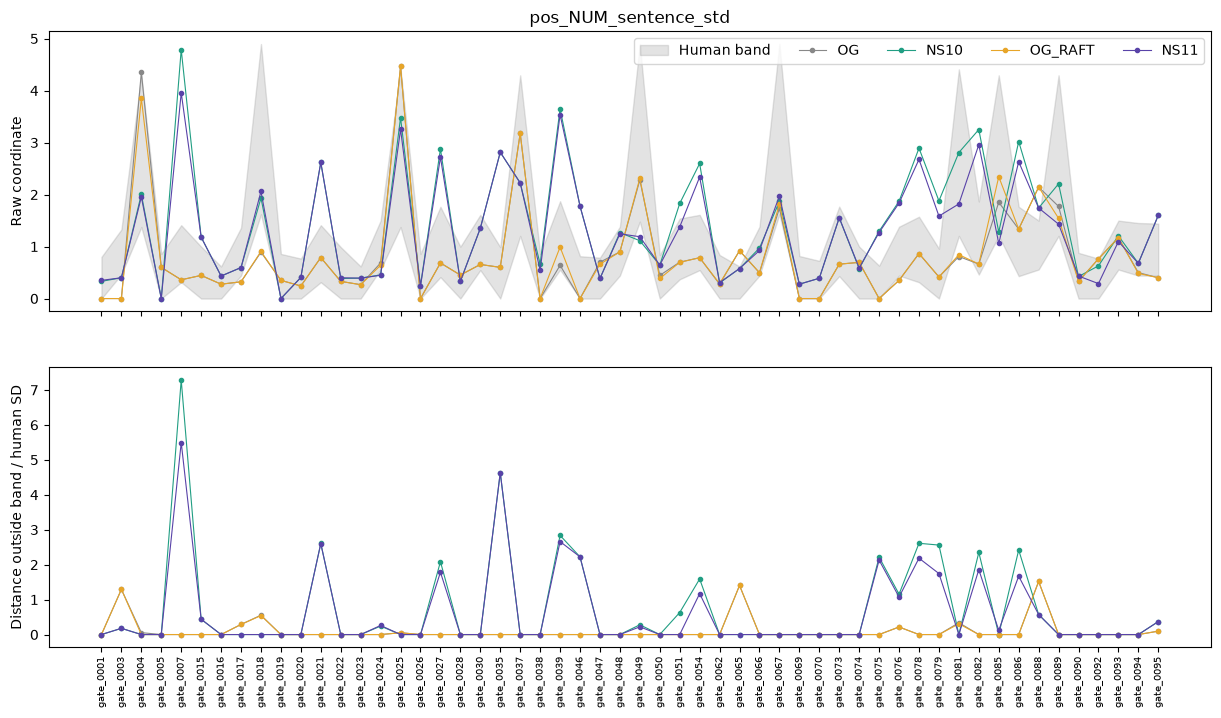

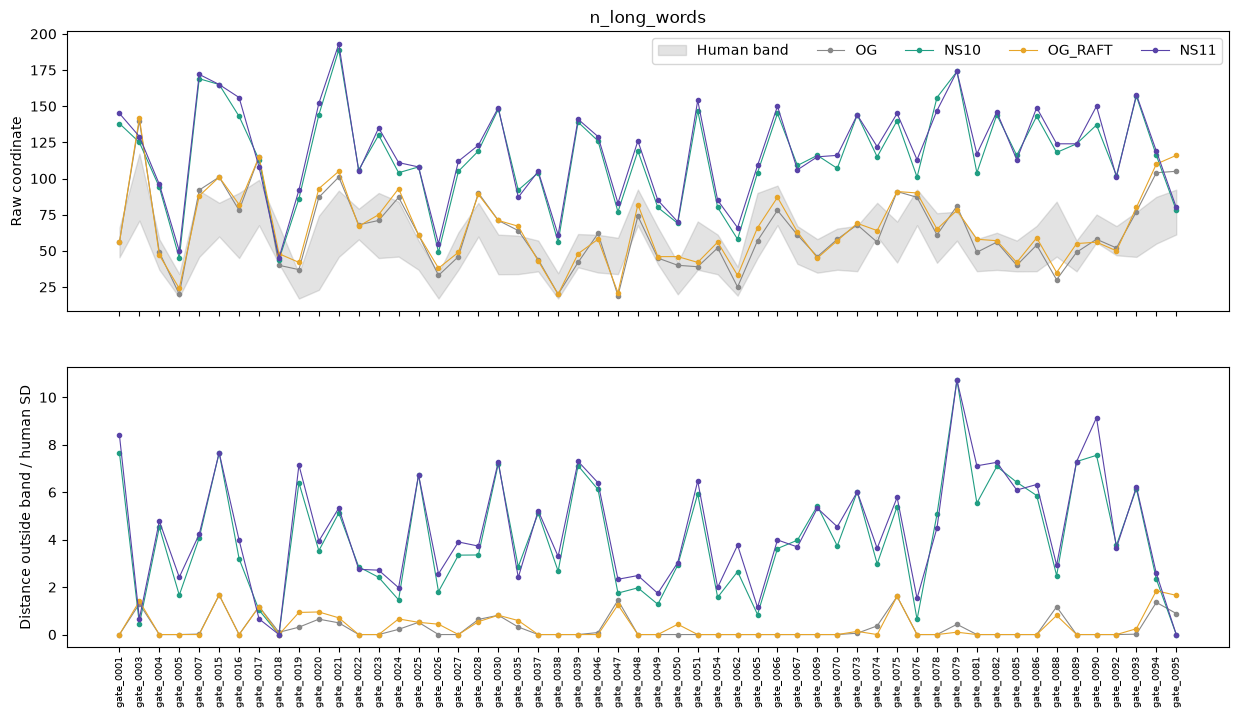

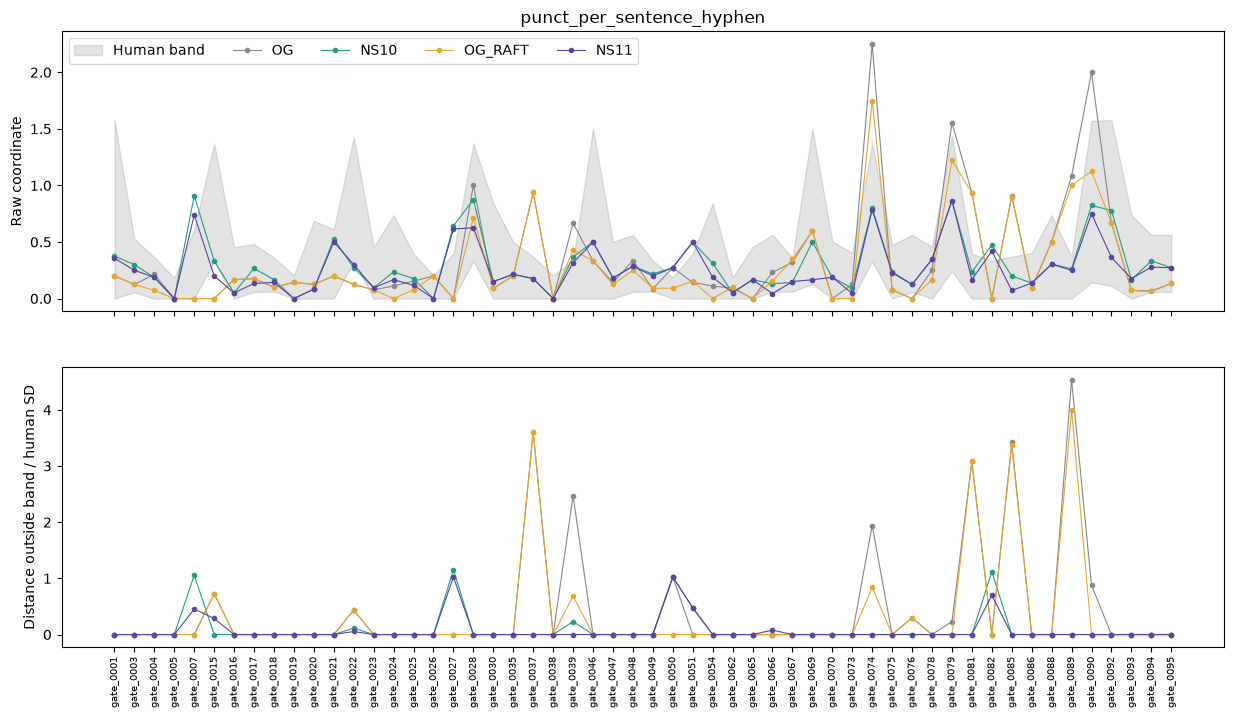

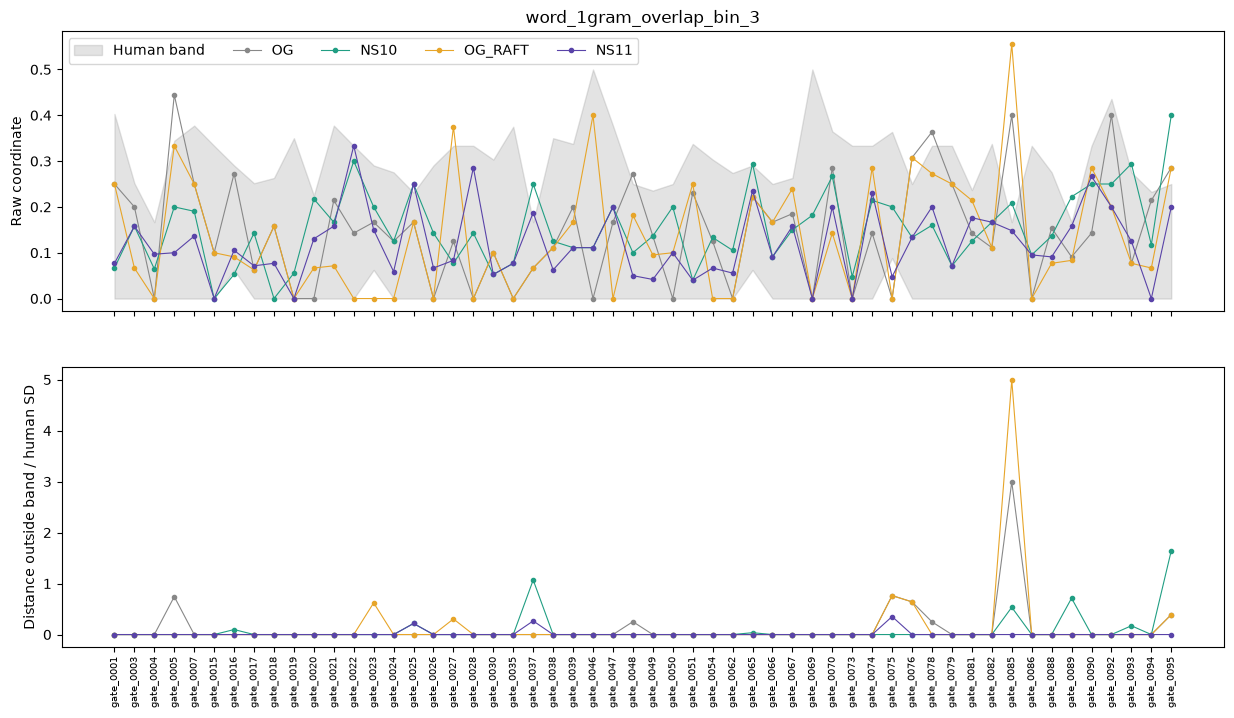

Saved: ../results/causal/C09c_FZ301_band_attainment_v1/frozen_FZ301_contributions
Intervals are pointwise, conditional on the frozen model and human pool. Rankings are descriptive. Tree-path contributions are additive score attributions, not causal effects of editing a feature.


In [9]:
# C09c — detector-relevant FZ301 contributions, following C04
from pathlib import Path
import json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TOP, B, SEED = 25, 2000, 20261004
ARMS = ["OG", "NS10", "OG_RAFT", "NS11"]
COLORS = dict(zip(ARMS, ["#888888", "#219e83", "#e7a529", "#5943a8"]))
AUDIT = OUT / "frozen_FZ301_contributions"
AUDIT.mkdir(parents=True, exist_ok=True)

# Locate the same accepted frozen C04 model used by C06b.
accepted = []
for p in (R / "C04_fz301_raid_fixed54").glob("*/stage_summary.csv"):
    s = pd.read_csv(p)
    if (
        len(s) == 3
        and np.isclose(s.iloc[0].AUROC, .875380, atol=5e-6)
        and np.isclose(s.iloc[2].AUROC, .699558, atol=5e-6)
    ):
        accepted.append(p.parent)
assert len(accepted) == 1, f"Expected one accepted C04 run: {accepted}"
C04 = accepted[0]

with (C04 / "FZ301.pkl").open("rb") as f:
    model = pickle.load(f)

cols = list(model.feature_names_in_)
assert len(cols) == 301
assert list(model.classes_) == [0, 1]
contract = json.loads((C04 / "contract.json").read_text())
manifest = json.loads((C04 / "feature_manifest.json").read_text())
assert cols == manifest["feature_names"]

# Cached C09c arm features.
features = pd.read_parquet(OUT / "all_features.parquet")
frames = {
    a: features.loc[features.arm.eq(a)]
       .sort_values("case_id").reset_index(drop=True)
    for a in ARMS
}
keys = ["case_id", "source_id", "domain"]
for a, frame in frames.items():
    assert len(frame) == 54 and frame.case_id.is_unique
    assert frame[keys].equals(frames["OG"][keys]), a
    assert np.isfinite(frame[cols].to_numpy(float)).all()

# Historical C04 test-human reference: identical for all four arms.
base_features = pd.read_parquet(BASE / "fz118_paired_features.parquet")
extension = pd.read_parquet(
    R / "C04_fz301_feature_cache"
    / contract["feature_manifest_hash"] / "raid_extensions.parquet"
)
hm = pd.read_csv(C04 / "human_test_manifest.csv")
assert hm.source_id.is_unique
assert base_features.source_id.is_unique and extension.source_id.is_unique

base_index = base_features.set_index("source_id")
ext_index = extension.set_index("source_id")
human_meta = base_index.loc[hm.source_id]
assert human_meta.label.eq(0).all() and human_meta.split.eq("test").all()

human_x = pd.DataFrame(index=hm.source_id)
for name in cols:
    source = base_index if name in base_index.columns else ext_index
    human_x[name] = source.loc[hm.source_id, name].to_numpy(float)
assert np.isfinite(human_x.to_numpy()).all()

# Exact additive decomposition of forest AI probability, as in C04.
def forest_contributions(model, frame):
    x = np.asarray(frame, dtype=np.float32)
    contribution = np.zeros(x.shape, dtype=float)
    bias = 0.0
    for estimator in model.estimators_:
        tree = estimator.tree_
        values = tree.value[:, 0, :].astype(float)
        probability = values[:, 1] / values.sum(axis=1)
        bias += probability[0] / len(model.estimators_)
        for i, row in enumerate(x):
            node = 0
            while tree.children_left[node] != tree.children_right[node]:
                j = tree.feature[node]
                child = (
                    tree.children_left[node]
                    if row[j] <= tree.threshold[node]
                    else tree.children_right[node]
                )
                contribution[i, j] += (
                    probability[child] - probability[node]
                ) / len(model.estimators_)
                node = child
    predictions = model.predict_proba(frame)[:, 1]
    np.testing.assert_allclose(
        bias + contribution.sum(axis=1),
        predictions, atol=1e-8, rtol=0,
    )
    return contribution, bias, predictions

hc, bias, hp = forest_contributions(model, human_x[cols])
human_reference = (
    pd.DataFrame(hc, columns=cols)
    .assign(domain=human_meta.domain.to_numpy())
    .groupby("domain")[cols].mean()
)
human_scores = (
    pd.DataFrame({
        "domain": human_meta.domain.to_numpy(),
        "AI_score": hp,
    }).groupby("domain").AI_score.mean()
)

domains = frames["OG"].domain.to_numpy()
assert set(domains) <= set(human_reference.index)
reference = human_reference.loc[domains, cols].to_numpy()
reference_score = human_scores.loc[domains].to_numpy()

# Shared genre-stratified bootstrap draws preserve pairing across arms.
rng = np.random.default_rng(SEED)
draws = np.concatenate([
    rng.choice(ix, size=(B, len(ix)), replace=True)
    for domain in sorted(set(domains))
    for ix in [np.flatnonzero(domains == domain)]
], axis=1)

def mean_ci(values):
    # Loop over replicates to avoid a large B × cases × features allocation.
    boot = np.vstack([values[ix].mean(axis=0) for ix in draws])
    lo, hi = np.quantile(boot, [.025, .975], axis=0)
    return values.mean(axis=0), lo, hi

gaps, rankings, scores = {}, [], []
for arm in ARMS:
    contribution, arm_bias, prediction = forest_contributions(
        model, frames[arm][cols]
    )
    assert np.isclose(arm_bias, bias)
    gaps[arm] = contribution - reference

    # Contributions must reconstruct the human-adjusted AI score exactly.
    np.testing.assert_allclose(
        gaps[arm].sum(axis=1), prediction - reference_score,
        atol=1e-8, rtol=0,
    )
    mean, lo, hi = mean_ci(gaps[arm])
    ranking = pd.DataFrame({
        "arm": arm, "feature": cols,
        "mean_contribution_gap": mean,
        "ci_low": lo, "ci_high": hi,
        "positive_case_fraction": (gaps[arm] > 0).mean(axis=0),
    })
    rankings.append(ranking)
    scores.append(pd.DataFrame({
        "case_id": frames[arm].case_id,
        "domain": domains,
        "arm": arm,
        "AI_score": prediction,
        "human_reference_score": reference_score,
        "human_adjusted_AI_score": prediction - reference_score,
    }))
    pd.DataFrame(gaps[arm], columns=cols).assign(
        case_id=frames[arm].case_id.to_numpy()
    ).to_csv(AUDIT / f"{arm}_case_contribution_gaps.csv", index=False)

ranking = pd.concat(rankings, ignore_index=True)
scores = pd.concat(scores, ignore_index=True)
ranking.to_csv(AUDIT / "all_arm_contribution_rankings.csv", index=False)
scores.to_csv(AUDIT / "case_AI_scores.csv", index=False)
human_reference.to_csv(AUDIT / "fixed_human_reference_contributions.csv")

print("Frozen FZ301 scores; positive adjusted values mean more AI-directed:")
display(scores.groupby("arm")[
    ["AI_score", "human_adjusted_AI_score"]
].mean().reindex(ARMS).round(5))

delta = gaps["NS11"] - gaps["NS10"]
mean, lo, hi = mean_ci(delta)
change = pd.DataFrame({
    "feature": cols,
    "delta_NS11_minus_NS10": mean,
    "ci_low": lo,
    "ci_high": hi,
    "fraction_cases_increased": (delta > 0).mean(axis=0),
}).sort_values("delta_NS11_minus_NS10", ascending=False)
change.to_csv(AUDIT / "RAFT_composition_contribution_changes.csv", index=False)

def positive_top(arm):
    p = ranking.loc[
        ranking.arm.eq(arm) & ranking.mean_contribution_gap.gt(0)
    ]
    return p.nlargest(TOP, "mean_contribution_gap").feature.tolist()

sets = {
    "OG_original_signals": positive_top("OG"),
    "NS11_remaining_signals": positive_top("NS11"),
    "RAFT_composition_increases": change.loc[
        change.delta_NS11_minus_NS10.gt(0), "feature"
    ].head(TOP).tolist(),
}

# All four arms on each feature-ranking graph.
for name, selected in sets.items():
    if not selected:
        print(name, ": no positive features.")
        continue
    fig, ax = plt.subplots(figsize=(12, max(5, .38 * len(selected))))
    y = np.arange(len(selected))
    for offset, arm in zip([-.27, -.09, .09, .27], ARMS):
        p = ranking.loc[ranking.arm.eq(arm)].set_index("feature").loc[selected]
        # Draw interval endpoints directly: no assumption that a percentile
        # bootstrap interval contains the point estimate.
        ax.hlines(y + offset, p.ci_low, p.ci_high, color=COLORS[arm], lw=1)
        ax.plot(
            p.mean_contribution_gap, y + offset, "o",
            color=COLORS[arm], ms=4, label=arm,
        )
    ax.axvline(0, color="black", lw=.8)
    ax.set_yticks(y, selected, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("Contribution to AI probability − same-genre human contribution")
    ax.set_title(name.replace("_", " "))
    ax.legend(ncol=4)
    ax.grid(axis="x", alpha=.2)
    fig.tight_layout()
    for ext in ["png", "pdf"]:
        fig.savefig(AUDIT / f"{name}.{ext}", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("\nLargest AI-contribution increases after adding RAFT:")
display(change.head(TOP).round(6))

# Connect detector relevance with the existing coordinate-band audit.
# Band references remain C09c's training-human diagnostic bands;
# contribution references above are historical C04 test humans.
events = pd.read_csv(OUT / "paired_events.csv")
events = events.loc[
    events["mode"].eq("length_matched") & np.isclose(events.q, .10)
]
event_summary = events.groupby("feature")[
    ["NS10_attained_then_lost", "NS10_inside_then_lost",
     "complementary_attainment", "eligible_NS10_inside"]
].sum()

joined = (
    change.set_index("feature")
    .join(event_summary)
    .join(
        ranking.pivot(
            index="feature", columns="arm", values="mean_contribution_gap"
        ).add_prefix("contribution_")
    )
)
joined.to_csv(AUDIT / "contribution_changes_with_band_events.csv")
display(joined.head(TOP).round(5))

# Plot raw values + human bands for the five largest contribution increases.
# Uses C09c's existing plot_coordinate helper; no new extraction.
if "plot_coordinate" in globals():
    for feature in sets["RAFT_composition_increases"][:5]:
        plot_coordinate(feature)

print("Saved:", AUDIT)
print(
    "Intervals are pointwise, conditional on the frozen model and human pool. "
    "Rankings are descriptive. Tree-path contributions are additive score "
    "attributions, not causal effects of editing a feature."
)

In [15]:
# %pip install "transformers==4.51.3"

In [1]:
from pathlib import Path
from transformers import Qwen3ForCausalLM  # confirms Qwen3 support

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "results/causal/C02d2_fz118_ghostbuster_raid").exists()
)
R = ROOT / "results/causal"
BASE = R / "C02d2_fz118_ghostbuster_raid"
OUT = R / "C09c_FZ301_band_attainment_v1"

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Re-download the exact U04 scorer checkpoint.
# A subprocess avoids any offline settings already cached by this kernel.
import os, subprocess, sys

env = os.environ.copy()
env["HF_HUB_OFFLINE"] = "0"
env["TRANSFORMERS_OFFLINE"] = "0"

subprocess.run(
    [
        sys.executable, "-c",
        """
from huggingface_hub import snapshot_download

path = snapshot_download(
    repo_id="Qwen/Qwen3-0.6B-Base",
    revision="da87bfb608c14b7cf20ba1ce41287e8de496c0cd",
    local_files_only=False,
    token=False,
    allow_patterns=["*.json", "*.safetensors", "*.txt", "*.model"],
    max_workers=2,
)
print("Restored scorer:", path)
"""
    ],
    env=env,
    check=True,
)

Restored scorer: /home/user/.cache/huggingface/hub/models--Qwen--Qwen3-0.6B-Base/snapshots/da87bfb608c14b7cf20ba1ce41287e8de496c0cd


Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 3437.15it/s]


CompletedProcess(args=['/home/user/Downloads/TemporalContextResearch/.venv/bin/python', '-c', '\nfrom huggingface_hub import snapshot_download\n\npath = snapshot_download(\n    repo_id="Qwen/Qwen3-0.6B-Base",\n    revision="da87bfb608c14b7cf20ba1ce41287e8de496c0cd",\n    local_files_only=False,\n    token=False,\n    allow_patterns=["*.json", "*.safetensors", "*.txt", "*.model"],\n    max_workers=2,\n)\nprint("Restored scorer:", path)\n'], returncode=0)

Using cached U04 scorer: /home/user/.cache/huggingface/hub/models--Qwen--Qwen3-0.6B-Base/snapshots/da87bfb608c14b7cf20ba1ce41287e8de496c0cd
Shared support: 39/54 cases


,case_id,arm,n_tokens,eligible
0,gate_0001,OG,156,False
3,gate_0005,OG,212,False
9,gate_0019,OG,162,False
12,gate_0022,OG,225,False
16,gate_0026,OG,216,False
18,gate_0028,OG,258,True
22,gate_0038,OG,142,False
23,gate_0039,OG,206,False
24,gate_0046,OG,151,False
25,gate_0047,OG,194,False


Uncached eligible documents: 185
U scoring: 10/185
U scoring: 20/185
U scoring: 30/185
U scoring: 40/185
U scoring: 50/185
U scoring: 60/185
U scoring: 70/185
U scoring: 80/185
U scoring: 90/185
U scoring: 100/185
U scoring: 110/185
U scoring: 120/185
U scoring: 130/185
U scoring: 140/185
U scoring: 150/185
U scoring: 160/185
U scoring: 170/185
U scoring: 180/185
U scoring: 185/185


arm,NS10,NS11,OG,OG_RAFT
metric,,,,
L128,2.6951,3.5757,1.7405,3.0208
L32,3.2715,4.0728,2.3834,3.4288
L8,4.1474,4.9426,3.3762,4.4040
U128,1.4522,1.3669,1.6357,1.3831
U32,0.8759,0.8698,0.9928,0.9751
extra_32_to_128,0.5763,0.4971,0.6429,0.4080


,metric,comparison,delta,ci_low,ci_high,positive_cases,negative_cases,cases
0,U128,NS10 minus OG,-0.18350,-0.52858,0.14690,18,21,39
1,U128,RAFT minus OG,-0.25260,-0.72438,0.25427,14,25,39
2,U128,NS11 minus NS10,-0.08533,-0.33820,0.18072,16,23,39
3,U128,composition interaction,0.16728,-0.38967,0.72421,23,16,39
4,U32,NS10 minus OG,-0.11689,-0.39080,0.16559,18,21,39
5,U32,RAFT minus OG,-0.01770,-0.29420,0.26994,16,23,39
6,U32,NS11 minus NS10,-0.00610,-0.25414,0.24630,21,18,39
7,U32,composition interaction,0.01160,-0.35453,0.39500,20,19,39
8,extra_32_to_128,NS10 minus OG,-0.06661,-0.25962,0.11945,18,21,39
9,extra_32_to_128,RAFT minus OG,-0.23490,-0.51975,0.09789,12,27,39


,metric,NS10_RMS_effect,RAFT_RMS_effect,effect_correlation,same_direction_fraction,nonzero_pairs
0,U128,1.1460,1.7641,0.4101,0.6410,39
1,U32,0.9462,0.9527,0.4097,0.6410,39
2,extra_32_to_128,0.7218,1.1739,0.4659,0.6410,39
3,L8,1.5964,2.3891,0.2615,0.6923,39
4,L32,1.5790,1.9585,0.2689,0.7179,39
5,L128,1.6609,1.8782,0.1766,0.7949,39


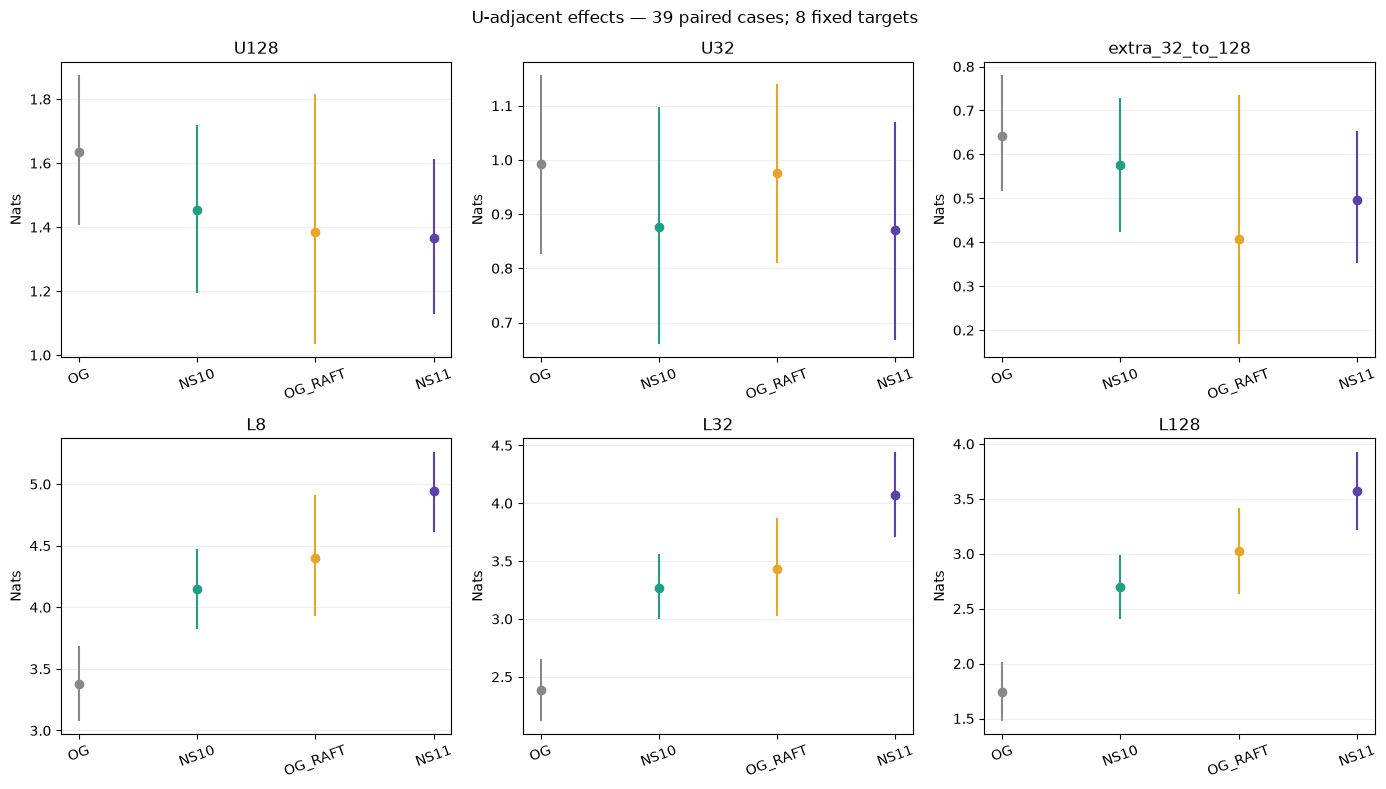

Saved: ../results/causal/C09c_FZ301_band_attainment_v1/U_overlap_v1
U32/U128 and their component losses are algebraically related, not independent features. Correlation shares the OG baseline and is descriptive. These measurements test effect overlap, not human-band attainment or the full class of U-adjacent features.


In [3]:
# C09c — U-adjacent overlap: OG, NS10, RAFT(OG), NS11
# Small frozen scorer; sequential, resumable inference. No training/generation.
from pathlib import Path
import json, hashlib, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display

UOUT = OUT / "U_overlap_v1"
UOUT.mkdir(parents=True, exist_ok=True)
ARMS = ["OG", "NS10", "OG_RAFT", "NS11"]
MODEL = "Qwen/Qwen3-0.6B-Base"
TARGETS = np.unique(np.linspace(128, 255, 8, dtype=int))
CONTEXTS = [8, 32, 128]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = (
    torch.bfloat16
    if DEVICE == "cuda" and torch.cuda.is_bf16_supported()
    else torch.float32
)
B, SEED = 5000, 20261004

# Reuse U04's recorded revision, never silently choose a new checkpoint.
pins = []
for p in (R / "U04_context_range_sweep_v1").rglob("scorer_pin.json"):
    obj = json.loads(p.read_text())
    if obj.get("model") == MODEL:
        pins.append((p, obj["revision"]))
assert pins, "Restore U04's scorer_pin.json before running this cell."
assert len({rev for _, rev in pins}) == 1, f"Conflicting U04 pins: {pins}"
REVISION = pins[0][1]

paths = {
    "NS10": R / "C06b_NEW_steps5_10_v1/NS10_texts.csv",
    "OG_RAFT": R / "R01_published_local_v3/RAFT_adaptation20_34/RAFT_texts54.csv",
    "NS11": R / "R11_NS10_RAFT_v1/NS11_texts.csv",
}
uf = {
    a: pd.read_csv(p, keep_default_na=False)
         .sort_values("case_id").reset_index(drop=True)
    for a, p in paths.items()
}
keys = ["case_id", "source_id", "domain"]
corpus_u = pd.read_parquet(BASE / "paired_corpus.parquet")
uf["OG"] = (
    uf["NS10"][keys]
    .merge(corpus_u[["source_id", "text"]], on="source_id",
           validate="one_to_one")
    .sort_values("case_id").reset_index(drop=True)
)
for a in ARMS:
    assert len(uf[a]) == 54 and uf[a].case_id.is_unique
    assert uf[a][keys].equals(uf["OG"][keys]), a
    assert uf[a].text.str.strip().ne("").all()

def uhash(x):
    return hashlib.sha256(str(x).encode()).hexdigest()

spec = dict(
    model=MODEL, revision=REVISION,
    targets=TARGETS.tolist(), contexts=CONTEXTS,
    dtype=str(DTYPE), device=DEVICE,
    transformers=transformers.__version__, torch=torch.__version__,
    normalization="CR/LF replaced by spaces",
    attention="eager", version=1,
)
signature = uhash(json.dumps(spec, sort_keys=True))
UCACHE = UOUT / "cache" / signature
UCACHE.mkdir(parents=True, exist_ok=True)
(UCACHE / "contract.json").write_text(json.dumps(spec, indent=2))

from huggingface_hub import snapshot_download

try:
    U_SCORER_PATH = snapshot_download(
        repo_id=MODEL,
        revision=REVISION,
        local_files_only=True,
    )
except Exception as e:
    raise RuntimeError(
        f"The U04 scorer revision is not available in this environment's "
        f"Hugging Face cache.\nModel: {MODEL}\nRevision: {REVISION}\n"
        "Use the same HF cache/environment as your successful U04 run, "
        "or restore that checkpoint. Do not substitute another scorer."
    ) from e

print("Using cached U04 scorer:", U_SCORER_PATH)

tok_u = AutoTokenizer.from_pretrained(
    U_SCORER_PATH, local_files_only=True
)
records, missing, lengths = [], {}, []
for arm in ARMS:
    for row in uf[arm].itertuples():
        text = str(row.text).replace("\n", " ").replace("\r", " ")
        h = uhash(text)
        ids = tok_u(text, add_special_tokens=False)["input_ids"]
        lengths.append(dict(
            case_id=row.case_id, arm=arm, n_tokens=len(ids),
            eligible=len(ids) >= 256,
        ))
        records.append(dict(
            case_id=row.case_id, source_id=row.source_id,
            domain=row.domain, arm=arm, text_sha=h,
        ))
        if len(ids) >= 256 and not (UCACHE / f"{h}.json").exists():
            missing[h] = ids[:256]

lengths = pd.DataFrame(lengths)
lengths.to_csv(UOUT / "length_audit.csv", index=False)
support = lengths.pivot(index="case_id", columns="arm", values="eligible")
eligible = support.index[support[ARMS].all(axis=1)].tolist()
assert eligible, "No cases support 256 tokens in all four arms."
print(f"Shared support: {len(eligible)}/54 cases")
display(lengths.loc[~lengths.case_id.isin(eligible)])
print("Uncached eligible documents:", len(missing))

# Only load the scorer when needed; one target at a time limits memory.
if missing:
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    lm_u = AutoModelForCausalLM.from_pretrained(
        U_SCORER_PATH,
        local_files_only=True,
        torch_dtype=DTYPE,
        low_cpu_mem_usage=True,
        attn_implementation="eager",
    ).to(DEVICE).eval()
    try:
        with torch.inference_mode():
            for i, (h, ids) in enumerate(missing.items(), 1):
                losses = {}
                for context in CONTEXTS:
                    vals = []
                    for j in TARGETS:
                        x = torch.tensor(
                            [ids[j-context:j]], device=DEVICE
                        )
                        y = torch.tensor([ids[j]], device=DEVICE)
                        result = lm_u(
                            input_ids=x, use_cache=False, logits_to_keep=1
                        )
                        vals.append(float(F.cross_entropy(
                            result.logits[:, -1].float(), y
                        ).item()))
                        del result, x, y
                    losses[str(context)] = vals
                record = {"text_sha": h, "losses": losses}
                p = UCACHE / f"{h}.json"
                tmp = p.with_suffix(".tmp")
                tmp.write_text(json.dumps(record, allow_nan=False))
                tmp.replace(p)
                if i % 10 == 0 or i == len(missing):
                    print(f"U scoring: {i}/{len(missing)}", flush=True)
    finally:
        del lm_u
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

rows = []
for r in records:
    if r["case_id"] not in eligible:
        continue
    cached = json.loads((UCACHE / f"{r['text_sha']}.json").read_text())
    assert cached["text_sha"] == r["text_sha"]
    losses = {k: np.asarray(v) for k, v in cached["losses"].items()}
    rows.append({
        **r,
        "L8": losses["8"].mean(),
        "L32": losses["32"].mean(),
        "L128": losses["128"].mean(),
        "U32": (losses["8"] - losses["32"]).mean(),
        "U128": (losses["8"] - losses["128"]).mean(),
        "extra_32_to_128": (losses["32"] - losses["128"]).mean(),
    })
ud = pd.DataFrame(rows)
ud.to_csv(UOUT / "per_case_metrics.csv", index=False)
metrics = ["U128", "U32", "extra_32_to_128", "L8", "L32", "L128"]

# Shared, genre-stratified case bootstrap.
case_order = sorted(eligible)
domains_u = (
    uf["OG"].set_index("case_id").loc[case_order, "domain"].to_numpy()
)
rng = np.random.default_rng(SEED)
draws_u = np.concatenate([
    rng.choice(ix, size=(B, len(ix)), replace=True)
    for domain in sorted(set(domains_u))
    for ix in [np.flatnonzero(domains_u == domain)]
], axis=1)

summary, changes, overlap = [], [], []
for metric in metrics:
    p = ud.pivot(index="case_id", columns="arm", values=metric)
    p = p.loc[case_order, ARMS]
    for arm in ARMS:
        v = p[arm].to_numpy()
        lo, hi = np.quantile(v[draws_u].mean(axis=1), [.025, .975])
        summary.append(dict(
            metric=metric, arm=arm, mean=v.mean(), ci_low=lo, ci_high=hi
        ))

    effects = {
        "NS10 minus OG": p.NS10 - p.OG,
        "RAFT minus OG": p.OG_RAFT - p.OG,
        "NS11 minus NS10": p.NS11 - p.NS10,
        "composition interaction":
            (p.NS11 - p.NS10) - (p.OG_RAFT - p.OG),
    }
    for name, d in effects.items():
        v = d.to_numpy()
        lo, hi = np.quantile(v[draws_u].mean(axis=1), [.025, .975])
        changes.append(dict(
            metric=metric, comparison=name, delta=v.mean(),
            ci_low=lo, ci_high=hi, positive_cases=int((v > 0).sum()),
            negative_cases=int((v < 0).sum()), cases=len(v),
        ))

    a = effects["NS10 minus OG"].to_numpy()
    b = effects["RAFT minus OG"].to_numpy()
    nonzero = (abs(a) > 1e-10) & (abs(b) > 1e-10)
    overlap.append(dict(
        metric=metric,
        NS10_RMS_effect=np.sqrt(np.mean(a*a)),
        RAFT_RMS_effect=np.sqrt(np.mean(b*b)),
        effect_correlation=(
            np.corrcoef(a, b)[0, 1]
            if np.std(a) > 0 and np.std(b) > 0 else np.nan
        ),
        same_direction_fraction=(
            np.mean(np.sign(a[nonzero]) == np.sign(b[nonzero]))
            if nonzero.any() else np.nan
        ),
        nonzero_pairs=int(nonzero.sum()),
    ))

summary = pd.DataFrame(summary)
changes = pd.DataFrame(changes)
overlap = pd.DataFrame(overlap)
summary.to_csv(UOUT / "summary.csv", index=False)
changes.to_csv(UOUT / "paired_changes.csv", index=False)
overlap.to_csv(UOUT / "effect_overlap.csv", index=False)

display(summary.pivot(index="metric", columns="arm", values="mean").round(4))
display(changes.round(5))
display(overlap.round(4))

colors_u = ["#888888", "#219e83", "#e7a529", "#5943a8"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, metric in zip(axes.flat, metrics):
    p = summary.loc[summary.metric.eq(metric)].set_index("arm").loc[ARMS]
    for j, (arm, color) in enumerate(zip(ARMS, colors_u)):
        ax.vlines(j, p.loc[arm, "ci_low"], p.loc[arm, "ci_high"], color=color)
        ax.plot(j, p.loc[arm, "mean"], "o", color=color)
    ax.set_xticks(range(4), ARMS, rotation=20)
    ax.set_title(metric)
    ax.set_ylabel("Nats")
    ax.grid(axis="y", alpha=.2)
fig.suptitle(f"U-adjacent effects — {len(eligible)} paired cases; 8 fixed targets")
fig.tight_layout()
for ext in ["png", "pdf"]:
    fig.savefig(UOUT / f"U_overlap.{ext}", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", UOUT)
print(
    "U32/U128 and their component losses are algebraically related, not "
    "independent features. Correlation shares the OG baseline and is descriptive. "
    "These measurements test effect overlap, not human-band attainment or "
    "the full class of U-adjacent features."
)

Attack support: 39 cases; with ≥10 human references: 39


,n_humans
case_id,
gate_0003,40
gate_0004,40
gate_0007,40
gate_0015,15
gate_0016,40
gate_0017,40
gate_0018,40
gate_0020,21
gate_0021,40


Human documents: 379; pending: 379
Human U: 10/379 saved
Human U: 20/379 saved
Human U: 30/379 saved
Human U: 40/379 saved
Human U: 50/379 saved
Human U: 60/379 saved
Human U: 70/379 saved
Human U: 80/379 saved
Human U: 90/379 saved
Human U: 100/379 saved
Human U: 110/379 saved
Human U: 120/379 saved
Human U: 130/379 saved
Human U: 140/379 saved
Human U: 150/379 saved
Human U: 160/379 saved
Human U: 170/379 saved
Human U: 180/379 saved
Human U: 190/379 saved
Human U: 200/379 saved
Human U: 210/379 saved
Human U: 220/379 saved
Human U: 230/379 saved
Human U: 240/379 saved
Human U: 250/379 saved
Human U: 260/379 saved
Human U: 270/379 saved
Human U: 280/379 saved
Human U: 290/379 saved
Human U: 300/379 saved
Human U: 310/379 saved
Human U: 320/379 saved
Human U: 330/379 saved
Human U: 340/379 saved
Human U: 350/379 saved
Human U: 360/379 saved
Human U: 370/379 saved
Human U: 379/379 saved


,metric,arm,cases,in_band_fraction,mean_distance_nats
0,L128,NS10,39,0.7436,0.1493
1,L128,NS11,39,0.4872,0.5047
2,L128,OG,39,0.4103,0.2976
3,L128,OG_RAFT,39,0.6410,0.3933
4,L32,NS10,39,0.8718,0.1083
5,L32,NS11,39,0.5128,0.5433
6,L32,OG,39,0.6667,0.1393
7,L32,OG_RAFT,39,0.7179,0.3387
8,L8,NS10,39,0.6923,0.1962
9,L8,NS11,39,0.5385,0.4426


,metric,transition,cases,gained,preserved,lost,crossed_entire_band,NS10_attained_then_NS11_lost
0,L128,OG → NS10,39,18,11,5,3,NaN
1,L128,OG → OG_RAFT,39,16,9,7,3,NaN
2,L128,NS10 → NS11,39,3,16,13,2,6.0
3,L32,OG → NS10,39,11,23,3,1,NaN
4,L32,OG → OG_RAFT,39,7,21,5,3,NaN
5,L32,NS10 → NS11,39,2,18,16,1,6.0
6,L8,OG → NS10,39,14,13,11,0,NaN
7,L8,OG → OG_RAFT,39,8,24,0,5,NaN
8,L8,NS10 → NS11,39,7,14,13,1,7.0
9,U128,OG → NS10,39,7,21,9,0,NaN


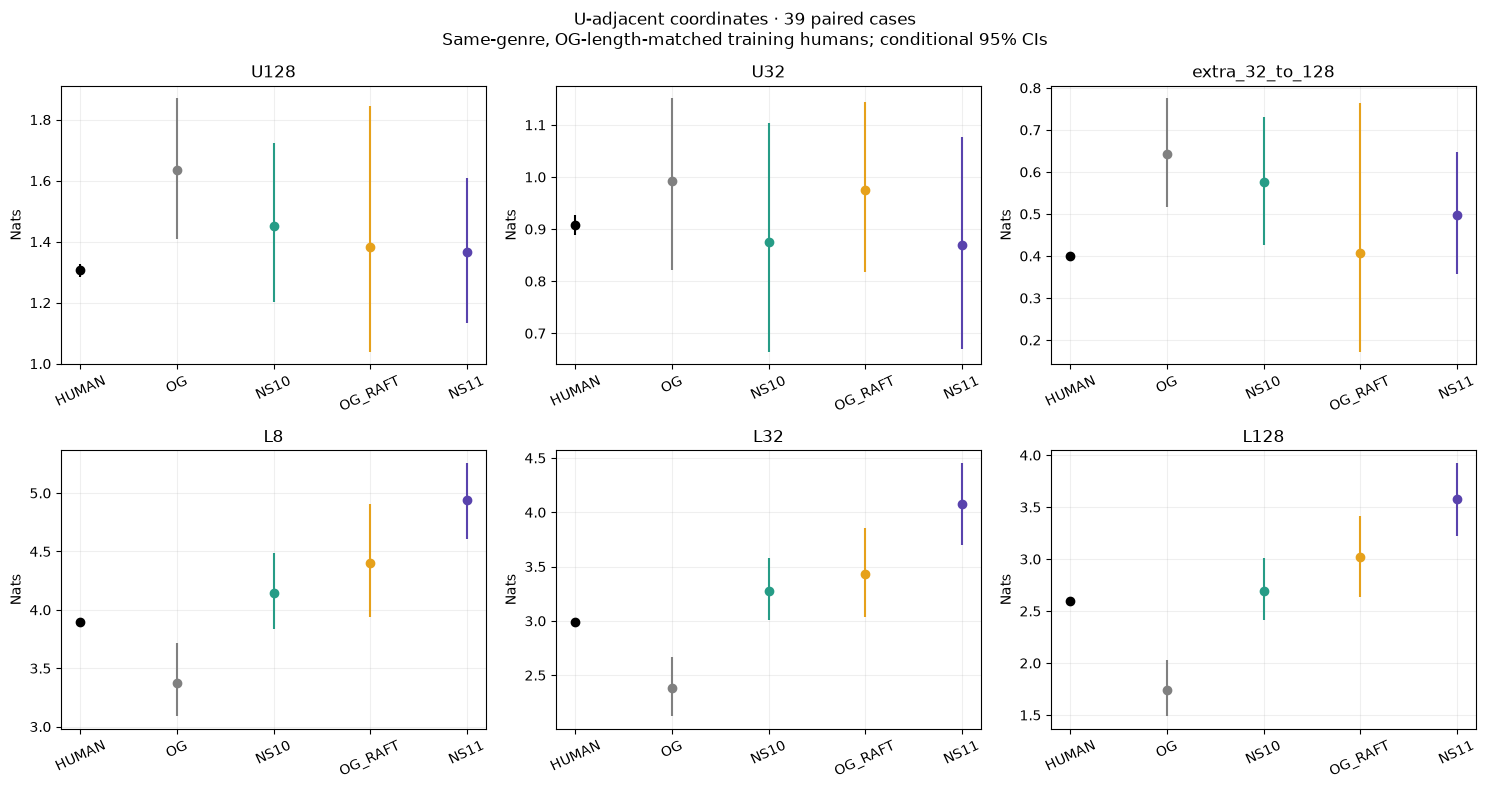

Saved: ../results/causal/C09c_FZ301_band_attainment_v1/U_overlap_v1/human_bands


In [4]:
# HUMAN reference bands for the existing U-overlap experiment.
import gc, hashlib, json, os
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from huggingface_hub import snapshot_download
from IPython.display import display

UOUT = OUT / "U_overlap_v1"
HOUT = UOUT / "human_bands"
HOUT.mkdir(parents=True, exist_ok=True)
ARMS_U = ["OG", "NS10", "OG_RAFT", "NS11"]
METRICS_U = ["U128", "U32", "extra_32_to_128", "L8", "L32", "L128"]
TARGETS_U = np.unique(np.linspace(128, 255, 8, dtype=int))
CONTEXTS_U = [8, 32, 128]
K_HUMAN, MIN_HUMAN = 40, 10
SEED_U = 20261004

# Reuse the scorer identity and compute dtype from the preceding cell.
assert "REVISION" in globals() and "DTYPE" in globals(), \
    "Run the preceding U-overlap cell first."
MODEL_U = "Qwen/Qwen3-0.6B-Base"
DEVICE_U = "cuda" if torch.cuda.is_available() else "cpu"
normalize_u = lambda s: str(s).replace("\r", " ").replace("\n", " ")
hash_u = lambda s: hashlib.sha256(s.encode()).hexdigest()

def atomic_u(path, obj):
    tmp = path.with_suffix(".tmp")
    tmp.write_text(json.dumps(obj, allow_nan=False))
    os.replace(tmp, path)

# Existing paired attack measurements: accept wide or long storage.
attack_u = pd.read_csv(UOUT / "per_case_metrics.csv",
                       dtype={"case_id": str})
if not set(METRICS_U).issubset(attack_u.columns):
    assert {"case_id", "arm", "metric", "value"}.issubset(attack_u.columns), \
        f"Unexpected saved columns: {attack_u.columns.tolist()}"
    attack_u = attack_u.pivot(
        index=["case_id", "arm"], columns="metric", values="value"
    ).reset_index()

attack_u = attack_u.loc[attack_u.arm.isin(ARMS_U)].copy()
assert not attack_u.duplicated(["case_id", "arm"]).any()
counts_u = attack_u.groupby("case_id").arm.nunique()
ids_u = sorted(counts_u[counts_u.eq(4)].index)
attack_u = attack_u.loc[attack_u.case_id.isin(ids_u)]
assert np.isfinite(attack_u[METRICS_U].to_numpy()).all()

meta_u = pd.read_parquet(BASE / "fz118_paired_features.parquet")
corpus_u = pd.read_parquet(BASE / "paired_corpus.parquet")
ns_u = pd.read_csv(
    R / "C06b_NEW_steps5_10_v1/NS10_texts.csv",
    dtype={"case_id": str}, keep_default_na=False
)
og_u = ns_u[["case_id", "source_id", "domain"]].merge(
    corpus_u[["source_id", "text"]], on="source_id", validate="one_to_one"
)
og_u = og_u.loc[og_u.case_id.isin(ids_u)].copy()
human_u = meta_u.loc[
    meta_u.dataset.eq("raid") & meta_u.split.eq("train") & meta_u.label.eq(0),
    ["source_id", "domain"]
].merge(corpus_u[["source_id", "text"]],
        on="source_id", validate="one_to_one")

local_u = snapshot_download(
    MODEL_U, revision=REVISION, local_files_only=True
)
tok_u = AutoTokenizer.from_pretrained(local_u, local_files_only=True)
for frame_u in [og_u, human_u]:
    frame_u["text"] = frame_u.text.map(normalize_u)
    frame_u["token_ids"] = [
        tok_u(t, add_special_tokens=False, truncation=False)["input_ids"]
        for t in frame_u.text
    ]
    frame_u["n_tokens"] = frame_u.token_ids.map(len)

# Eligibility precedes reference selection. Match full scorer-token length;
# all scored targets remain in the first 256 tokens, as in the attack run.
human_u = human_u.loc[human_u.n_tokens.ge(256)].copy()
members_u = []
for row_u in og_u.itertuples():
    candidates_u = human_u.loc[human_u.domain.eq(row_u.domain)].copy()
    candidates_u["length_distance"] = np.abs(
        np.log1p(candidates_u.n_tokens) - np.log1p(row_u.n_tokens)
    )
    candidates_u = candidates_u.sort_values(
        ["length_distance", "source_id"]
    ).head(K_HUMAN)
    for ref_u in candidates_u.itertuples():
        members_u.append(dict(
            case_id=row_u.case_id, domain=row_u.domain,
            reference_id=ref_u.source_id,
            length_distance=ref_u.length_distance
        ))

members_u = pd.DataFrame(members_u)
assert len(members_u), "No eligible same-genre human references."
members_u.to_csv(HOUT / "reference_membership.csv", index=False)
support_u = members_u.groupby("case_id").size()
valid_ids_u = sorted(support_u[support_u.ge(MIN_HUMAN)].index)
print(f"Attack support: {len(ids_u)} cases; "
      f"with ≥{MIN_HUMAN} human references: {len(valid_ids_u)}")
display(support_u.rename("n_humans").to_frame())
assert valid_ids_u, "Insufficient human reference support."

members_u = members_u.loc[members_u.case_id.isin(valid_ids_u)]
human_u = human_u.loc[
    human_u.source_id.isin(members_u.reference_id)
].copy()

# Human-only resumable cache; changing scorer/protocol creates a new cache.
import transformers
protocol_u = dict(
    model=MODEL_U, revision=REVISION, targets=TARGETS_U.tolist(),
    contexts=CONTEXTS_U, dtype=str(DTYPE), device=DEVICE_U,
    transformers=transformers.__version__, torch=torch.__version__,
    normalization="CR/LF to spaces", attention="eager",
    implementation="human_U_v1"
)
cache_u = HOUT / "cache" / hash_u(json.dumps(protocol_u, sort_keys=True))
cache_u.mkdir(parents=True, exist_ok=True)
atomic_u(cache_u / "protocol.json", protocol_u)
human_u["text_sha"] = human_u.text.map(hash_u)
unique_u = human_u.drop_duplicates("text_sha")
pending_u = [
    r for r in unique_u.itertuples()
    if not (cache_u / f"{r.text_sha}.json").exists()
]
print(f"Human documents: {len(unique_u)}; pending: {len(pending_u)}",
      flush=True)

if pending_u:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    scorer_u = AutoModelForCausalLM.from_pretrained(
        local_u, local_files_only=True, torch_dtype=DTYPE,
        low_cpu_mem_usage=True, attn_implementation="eager"
    ).to(DEVICE_U).eval()
    try:
        with torch.inference_mode():
            for i_u, row_u in enumerate(pending_u, 1):
                losses_u = {}
                for k_u in CONTEXTS_U:
                    vals_u = []
                    for t_u in TARGETS_U:
                        x_u = torch.tensor(
                            [row_u.token_ids[t_u-k_u:t_u]],
                            device=DEVICE_U
                        )
                        logits_u = scorer_u(
                            input_ids=x_u, use_cache=False,
                            logits_to_keep=1
                        ).logits[:, -1, :].float()
                        y_u = torch.tensor(
                            [row_u.token_ids[t_u]], device=DEVICE_U
                        )
                        vals_u.append(F.cross_entropy(logits_u, y_u).item())
                    losses_u[f"L{k_u}"] = float(np.mean(vals_u))
                losses_u.update(
                    U32=losses_u["L8"]-losses_u["L32"],
                    U128=losses_u["L8"]-losses_u["L128"],
                    extra_32_to_128=losses_u["L32"]-losses_u["L128"]
                )
                atomic_u(cache_u / f"{row_u.text_sha}.json", losses_u)
                if i_u % 10 == 0 or i_u == len(pending_u):
                    print(f"Human U: {i_u}/{len(pending_u)} saved", flush=True)
    finally:
        del scorer_u
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

human_scores_u = pd.DataFrame([
    dict(source_id=r.source_id, **json.loads(
        (cache_u / f"{r.text_sha}.json").read_text()
    )) for r in human_u.itertuples()
])
human_scores_u.to_csv(HOUT / "human_metrics.csv", index=False)
refs_u = members_u.merge(
    human_scores_u, left_on="reference_id", right_on="source_id",
    validate="many_to_one"
)

# One fixed human band per source and coordinate, shared by all arms.
bands_u = []
for cid_u, group_u in refs_u.groupby("case_id"):
    for metric_u in METRICS_U:
        v_u = group_u[metric_u].to_numpy(float)
        lo_u, med_u, hi_u = np.quantile(v_u, [.1, .5, .9])
        bands_u.append(dict(
            case_id=cid_u, metric=metric_u,
            low=lo_u, median=med_u, high=hi_u,
            human_mean=v_u.mean(), n_humans=len(v_u)
        ))
bands_u = pd.DataFrame(bands_u)
bands_u.to_csv(HOUT / "human_bands.csv", index=False)
long_u = attack_u.loc[attack_u.case_id.isin(valid_ids_u)].melt(
    id_vars=["case_id", "arm"], value_vars=METRICS_U,
    var_name="metric", value_name="value"
).merge(bands_u, on=["case_id", "metric"], validate="many_to_one")
long_u["state"] = np.where(
    long_u.value < long_u.low-1e-12, -1,
    np.where(long_u.value > long_u.high+1e-12, 1, 0)
)
long_u["inside"] = long_u.state.eq(0)
long_u["distance_nats"] = np.maximum(
    np.maximum(long_u.low-long_u.value, long_u.value-long_u.high), 0
)
long_u.to_csv(HOUT / "case_band_states.csv", index=False)

attain_u = long_u.groupby(["metric", "arm"]).agg(
    cases=("case_id", "size"),
    in_band_fraction=("inside", "mean"),
    mean_distance_nats=("distance_nats", "mean")
).reset_index()
display(attain_u.round(4))
attain_u.to_csv(HOUT / "attainment_summary.csv", index=False)

events_u = []
for metric_u, group_u in long_u.groupby("metric"):
    p_u = group_u.pivot(index="case_id", columns="arm", values="state")
    for before_u, after_u in [
        ("OG", "NS10"), ("OG", "OG_RAFT"), ("NS10", "NS11")
    ]:
        a_u, b_u = p_u[before_u], p_u[after_u]
        events_u.append(dict(
            metric=metric_u, transition=f"{before_u} → {after_u}",
            cases=len(p_u),
            gained=int(((a_u != 0) & (b_u == 0)).sum()),
            preserved=int(((a_u == 0) & (b_u == 0)).sum()),
            lost=int(((a_u == 0) & (b_u != 0)).sum()),
            crossed_entire_band=int((a_u*b_u == -1).sum()),
            NS10_attained_then_NS11_lost=int((
                (p_u.OG != 0) & (p_u.NS10 == 0) & (p_u.NS11 != 0)
            ).sum()) if before_u == "NS10" else np.nan
        ))
events_u = pd.DataFrame(events_u)
display(events_u)
events_u.to_csv(HOUT / "band_transitions.csv", index=False)

# HUMAN is the mean of each case's matched reference mean, so genres/cases
# receive exactly the same weighting as the attack arms.
# CIs resample cases within genre, conditional on fixed human references.
domains_u = og_u.set_index("case_id").loc[valid_ids_u, "domain"].to_numpy()
rng_u = np.random.default_rng(SEED_U)
strata_u = [np.flatnonzero(domains_u == d) for d in np.unique(domains_u)]
boot_u = np.concatenate([
    rng_u.choice(s, size=(2000, len(s)), replace=True) for s in strata_u
], axis=1)
colors_u = ["black", "gray", "#269c86", "#e6a11b", "#5943ad"]
fig_u, axes_u = plt.subplots(2, 3, figsize=(15, 8))
for ax_u, metric_u in zip(axes_u.flat, METRICS_U):
    human_mean_u = bands_u.loc[bands_u.metric.eq(metric_u)].set_index(
        "case_id"
    ).loc[valid_ids_u, "human_mean"].to_numpy()
    values_u = [human_mean_u] + [
        long_u.loc[
            long_u.metric.eq(metric_u) & long_u.arm.eq(a)
        ].set_index("case_id").loc[valid_ids_u, "value"].to_numpy()
        for a in ARMS_U
    ]
    for j_u, (v_u, color_u) in enumerate(zip(values_u, colors_u)):
        ci_u = np.quantile(v_u[boot_u].mean(axis=1), [.025, .975])
        ax_u.vlines(j_u, *ci_u, color=color_u)
        ax_u.plot(j_u, v_u.mean(), "o", color=color_u)
    ax_u.set_xticks(range(5), ["HUMAN"] + ARMS_U, rotation=25)
    ax_u.set_title(metric_u)
    ax_u.set_ylabel("Nats")
    ax_u.grid(alpha=.2)
fig_u.suptitle(
    f"U-adjacent coordinates · {len(valid_ids_u)} paired cases\n"
    "Same-genre, OG-length-matched training humans; conditional 95% CIs"
)
fig_u.tight_layout()
fig_u.savefig(HOUT / "U_with_HUMAN.png", dpi=180, bbox_inches="tight")
fig_u.savefig(HOUT / "U_with_HUMAN.pdf", bbox_inches="tight")
plt.show()
print("Saved:", HOUT)